# Два новых датасета: регрессии групп и нелинейная зависимость

**Текущий выбор: MASS Crabs для первого задания и UCI Yacht Hydrodynamics для второго.**
Оба набора содержат реальные измерения. В первом проверяем две зависимости с разным
остаточным разбросом и обучаем смесь регрессий, скрыв метки групп. Во втором
преобразуем отклик и все предикторы, строим линейную модель в новом пространстве
и измеряем вклад каждого физического фактора в качество прогноза.

Новые наборы отсутствуют среди **59 названий на четырёх фотографиях каталога преподавателя**.
Список сохранён в `data/teacher_dataset_exclusions.json`; номера 47 на фото нет.
Пингвины и Abalone в этом списке есть, поэтому они сохранены ниже только в архиве.
Прежнее требование «остальные признаки бесполезны» заменено оценкой **размера их вклада**.

Все сравнения используют фиксированное разбиение с seed=42. Выводы кода — графики,
пояснения — Markdown. Код свёрнут и доступен для проверки. Архивные расчёты сохранены
после текущего вывода; их прежние решения не являются рекомендациями этой версии.

In [1]:
%matplotlib inline
# Библиотеки и воспроизводимость
from pathlib import Path
import json

import matplotlib
if "__file__" in globals():
    matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
from scipy.special import logsumexp
from scipy.stats import chi2, levene, multivariate_normal, t
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.mixture import GaussianMixture
from sklearn.model_selection import KFold, train_test_split

BASE = Path(__file__).resolve().parent if "__file__" in globals() else Path.cwd()
OUT = BASE / "outputs"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
COLORS = {"Adelie": "#2769A3", "Gentoo": "#C77824", "Chinstrap": "#77549B"}
BLUE, ORANGE, GREEN, RED = "#2769A3", "#C77824", "#007F73", "#C94A3D"
plt.rcParams.update({
    "font.family": "DejaVu Sans", "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.axisbelow": True, "grid.alpha": .25,
})
results = {}


def figure(fig, name):
    fig.savefig(FIG / name, dpi=150, bbox_inches="tight")
    if "__file__" not in globals():
        plt.show()
    plt.close(fig)


def design(x):
    x = np.asarray(x, dtype=float)
    if x.ndim == 1:
        x = x[:, None]
    return np.column_stack([np.ones(len(x)), x])


def ols(x, y):
    X, y = design(x), np.asarray(y, dtype=float)
    beta = np.linalg.lstsq(X, y, rcond=None)[0]
    error = y - X @ beta
    df = len(y) - np.linalg.matrix_rank(X)
    inv = np.linalg.pinv(X.T @ X)
    h = np.einsum("ij,jk,ik->i", X, inv, X)
    mse = error @ error / df
    adjusted = error / np.maximum(1 - h, 1e-9)
    cov = inv @ (X.T @ ((adjusted**2)[:, None] * X)) @ inv
    return {"beta": beta, "cov": cov, "classical_cov": mse * inv,
            "mse": mse, "df": df, "error": error, "n": len(y),
            "r2": r2_score(y, X @ beta)}


def predict(fit, x):
    return design(x) @ fit["beta"]


def interval(fit, x, observation=False):
    X = design(x)
    covariance = fit["classical_cov"] if observation else fit["cov"]
    variance = np.einsum("ij,jk,ik->i", X, covariance, X)
    if observation:
        variance += fit["mse"]
    half = t.ppf(.975, fit["df"]) * np.sqrt(np.maximum(variance, 0))
    center = X @ fit["beta"]
    return center - half, center + half


def coefficient_ci(fit):
    half = t.ppf(.975, fit["df"]) * np.sqrt(np.maximum(np.diag(fit["cov"]), 0))
    return np.column_stack([fit["beta"] - half, fit["beta"] + half])

## 1. MASS Crabs: две формы крабов, две регрессии

[Документация MASS](https://stat.ethz.ch/R-manual/R-devel/library/MASS/html/crabs.html)
описывает 200 крабов из Фримантла, Австралия: синяя (`B`) и оранжевая (`O`)
цветовые формы, по 50 особей каждого пола внутри каждой формы. Источник исследования —
Campbell и Mahon (1974). Локальный CSV получен из [Rdatasets](https://vincentarelbundock.github.io/Rdatasets/csv/MASS/crabs.csv).

Пять размеров в миллиметрах: `FL` — фронтальный размер, `RW` — задняя ширина,
`CL` — длина панциря, `CW` — его ширина, `BD` — толщина тела. Выбираем
$x=CW$, $y=FL$; для множественной регрессии добавляем $RW$.
Метка формы нужна для проверки, пол — для стратифицированного разбиения;
`index` и `rownames` — служебные номера, предикторами не являются.
Пропусков, неположительных размеров и полных повторов измерений в файле нет.

Обучение — 140 крабов, тест — 60; каждая комбинация «форма × пол» представлена
35 и 15 объектами соответственно. Сначала сравниваем общую прямую
$FL=a+bCW+\varepsilon$ с двумя прямыми, каждая со своим остаточным $s$.
На следующем графике использовано только обучение; полосы — 95% прогнозные
интервалы отдельного измерения при нормальных независимых остатках внутри формы.

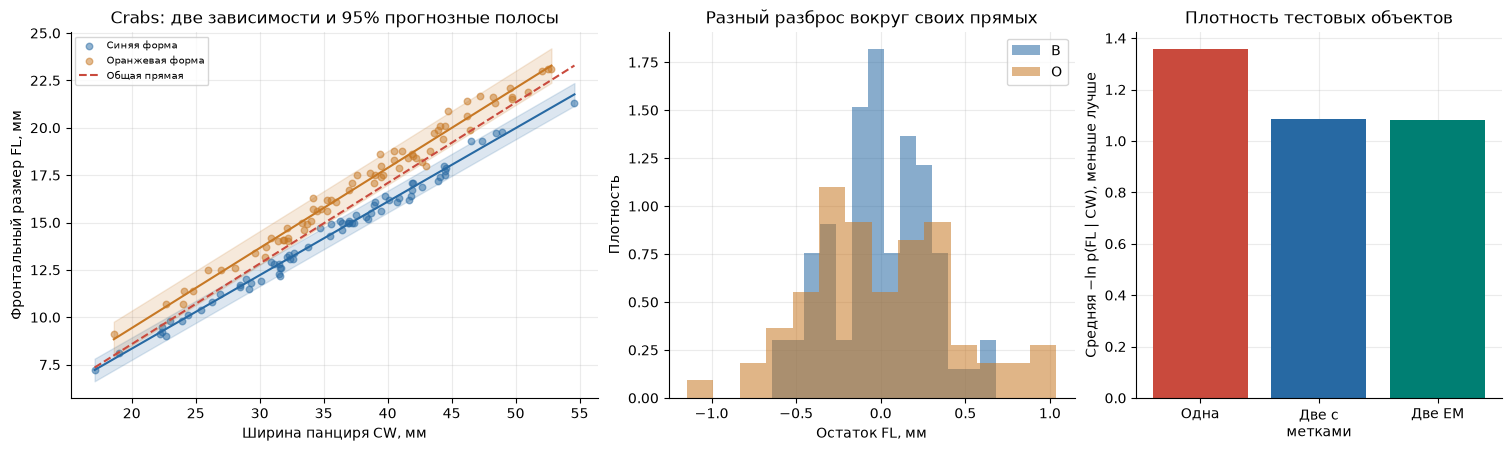

In [2]:
# Новые наборы: вспомогательные методы и смесь регрессий без меток групп
import math
from scipy.optimize import linear_sum_assignment
from scipy.stats import norm
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler, SplineTransformer
from sklearn.model_selection import StratifiedKFold, GroupKFold, GroupShuffleSplit
from sklearn.metrics import balanced_accuracy_score, adjusted_rand_score
from sklearn.ensemble import RandomForestRegressor

v2_results = {}

def v2_em_fit(x, y, starts=20, seed=42):
    x, y = np.asarray(x, float), np.asarray(y, float)
    if x.ndim == 1: x = x[:, None]
    xm, xs, ym, ys = x.mean(0), x.std(0), y.mean(), y.std()
    X, z = design((x-xm)/xs), (y-ym)/ys
    initial_error = z-X@np.linalg.lstsq(X, z, rcond=None)[0]
    rng, best = np.random.default_rng(seed), None
    for start in range(starts):
        if start < starts*3//4:
            e = initial_error+rng.normal(0, initial_error.std()*.2, len(y))
            cut = np.quantile(e, rng.uniform(.3, .7))
            resp = np.column_stack([e<=cut, e>cut]).astype(float)*.9+.05
        else:
            resp = rng.dirichlet([1, 1], len(y))
        trace = []
        for iteration in range(400):
            count = resp.sum(0)
            beta = np.stack([np.linalg.lstsq(X*np.sqrt(resp[:,k,None]), z*np.sqrt(resp[:,k]), rcond=None)[0] for k in range(2)])
            errors = z[:,None]-X@beta.T
            variance = np.maximum((resp*errors**2).sum(0)/count, 1e-4)
            weights = count/len(y)
            logs = np.log(weights)-.5*(np.log(2*np.pi*variance)+errors**2/variance)
            den = logsumexp(logs, axis=1)
            likelihood = float(den.sum())
            resp = np.exp(logs-den[:,None])
            trace.append({'ll': likelihood, 'beta': beta.copy(), 'variance': variance.copy()})
            if len(trace)>1 and abs(trace[-1]['ll']-trace[-2]['ll']) < 1e-8*(1+abs(trace[-2]['ll'])): break
        # Отбрасываем вырожденные решения, покрывающие лишь несколько объектов.
        if min(resp.sum(0)) < .10*len(y): continue
        if best is None or likelihood > best['ll']:
            best = dict(ll=likelihood, beta=beta, variance=variance, weights=weights,
                        resp=resp, trace=trace, xm=xm, xs=xs, ym=ym, ys=ys)
    if best is None: raise RuntimeError('Не найдено невырожденной смеси двух регрессий')
    return best

def v2_em_raw(model, state=None):
    beta = model['beta'] if state is None else state['beta']
    variance = model['variance'] if state is None else state['variance']
    slopes = model['ys']*beta[:,1:]/model['xs']
    intercepts = model['ym']+model['ys']*beta[:,0]-slopes@model['xm']
    return np.column_stack([intercepts, slopes]), model['ys']*np.sqrt(variance)

def v2_em_prob(model, x, y):
    beta, sigma = v2_em_raw(model)
    means = design(x)@beta.T
    logs = np.log(model['weights'])+norm.logpdf(np.asarray(y)[:,None], means, sigma)
    return np.exp(logs-logsumexp(logs, axis=1)[:,None]), logsumexp(logs, axis=1)

def v2_component_names(model, truth):
    hard = model['resp'].argmax(1)
    counts = np.bincount(2*np.asarray(truth)+hard, minlength=4).reshape(2,2)
    rows, cols = linear_sum_assignment(-counts)
    return {int(k): int(c) for c,k in zip(rows, cols)}

def v2_weighted_quantile(x, weights, probs):
    order = np.argsort(x)
    x, weights = np.asarray(x)[order], np.asarray(weights)[order]
    cdf = (np.cumsum(weights)-.5*weights)/weights.sum()
    return np.interp(probs, cdf, x)

def v2_wilson(success, count):
    p, z = success/count, norm.ppf(.975)
    center = (p+z*z/(2*count))/(1+z*z/count)
    half = z*np.sqrt(p*(1-p)/count+z*z/(4*count*count))/(1+z*z/count)
    return [max(0., center-half), min(1., center+half)]

v2_crabs = pd.read_csv(BASE/'data/crabs.csv')
assert len(v2_crabs)==200 and not v2_crabs.isna().any().any()
assert v2_crabs[['FL','RW','CL','CW','BD']].gt(0).all().all()
assert not v2_crabs[['sp','sex','FL','RW','CL','CW','BD']].duplicated().any()
v2_ctr, v2_cte = train_test_split(v2_crabs, test_size=.30, random_state=SEED,
                                stratify=v2_crabs.sp+v2_crabs.sex)
v2_ct = v2_ctr.sp.eq('O').astype(int).to_numpy()
v2_cy = v2_cte.sp.eq('O').astype(int).to_numpy()
v2_csingle = ols(v2_ctr.CW, v2_ctr.FL)
v2_cseparate = {s: ols(d.CW,d.FL) for s,d in v2_ctr.groupby('sp')}
v2_cmulti = {s: ols(d[['CW','RW']],d.FL) for s,d in v2_ctr.groupby('sp')}
v2_cem = v2_em_fit(v2_ctr[['CW']], v2_ctr.FL, seed=SEED)
v2_cem_multi = v2_em_fit(v2_ctr[['CW','RW']], v2_ctr.FL, seed=SEED)
v2_cmap = v2_component_names(v2_cem, v2_ct)
v2_cmap_multi = v2_component_names(v2_cem_multi, v2_ct)
v2_cscore = ols(v2_ctr[['CW','FL']], v2_ct)
v2_class_prediction = {'Одна регрессия метки': (predict(v2_cscore,v2_cte[['CW','FL']])>=.5).astype(int)}
v2_known_logs = np.column_stack([norm.logpdf(v2_cte.FL, predict(v2_cseparate[s],v2_cte.CW), np.sqrt(v2_cseparate[s]['mse'])) for s in ['B','O']])
v2_known_logs += np.log([v2_ctr.sp.eq(s).mean() for s in ['B','O']])
v2_class_prediction['Две, метки известны'] = v2_known_logs.argmax(1)
for name, model, mapping, features in [('EM, один X',v2_cem,v2_cmap,['CW']), ('EM, два X',v2_cem_multi,v2_cmap_multi,['CW','RW'])]:
    prob, _ = v2_em_prob(model,v2_cte[features],v2_cte.FL)
    v2_class_prediction[name] = np.array([mapping[k] for k in prob.argmax(1)])
v2_centers = np.stack([v2_ctr.loc[v2_ctr.sp.eq(s),['CW','FL']].mean().to_numpy() for s in ['B','O']])
v2_center_scale = v2_ctr[['CW','FL']].std(ddof=0).to_numpy()
v2_nearest = (((v2_cte[['CW','FL']].to_numpy()[:,None,:]-v2_centers)/v2_center_scale)**2).sum(2).argmin(1)
v2_class_prediction = {'Ближайший центр':v2_nearest, **v2_class_prediction}

def v2_crab_compatible(x, y, mode):
    x, y = np.asarray(x), np.asarray(y)
    accepted = []
    for cls,s in enumerate(['B','O']):
        if mode=='known':
            fit = v2_cseparate[s]
            low,high = interval(fit,x,observation=True)
            xr = v2_ctr.loc[v2_ctr.sp.eq(s),'CW']
            bounds = [xr.min(),xr.max()]
        else:
            k = next(k for k,c in v2_cmap.items() if c==cls)
            beta,sigma = v2_em_raw(v2_cem)
            mean = beta[k,0]+beta[k,1]*x
            low,high = mean-1.96*sigma[k],mean+1.96*sigma[k]
            bounds = v2_weighted_quantile(v2_ctr.CW,v2_cem['resp'][:,k],[.005,.995])
        accepted.append((x>=bounds[0])&(x<=bounds[1])&(y>=low)&(y<=high))
    return accepted[0].astype(int)+2*accepted[1].astype(int)

v2_cdec = v2_crab_compatible(v2_cte.CW,v2_cte.FL,'em')
v2_cbeta,v2_csigma = v2_em_raw(v2_cem)
v2_c_density = {'Одна нормальная регрессия': -float(norm.logpdf(v2_cte.FL,predict(v2_csingle,v2_cte.CW),np.sqrt(v2_csingle['mse'])).mean()),
                'Две, метки известны': -float(logsumexp(v2_known_logs,axis=1).mean()),
                'Две EM, метки скрыты': -float(v2_em_prob(v2_cem,v2_cte[['CW']],v2_cte.FL)[1].mean())}
v2_cstats = {
    'counts': v2_crabs.groupby(['sp','sex']).size().astype(int).to_dict(),
    'train':len(v2_ctr),'test':len(v2_cte),
    'single_beta':v2_csingle['beta'].tolist(),
    'regressions':{s:{'beta':f['beta'].tolist(),'r2':f['r2'],'sigma':float(np.sqrt(f['mse'])),'slope_ci':coefficient_ci(f)[1].tolist()} for s,f in v2_cseparate.items()},
    'multiple':{s:{'beta':f['beta'].tolist(),'r2':f['r2'],'sigma':float(np.sqrt(f['mse']))} for s,f in v2_cmulti.items()},
    'em':{['B','O'][cls]:{'beta':v2_cbeta[k].tolist(),'sigma':float(v2_csigma[k]),'weight':float(v2_cem['weights'][k])} for k,cls in v2_cmap.items()},
    'em_iterations':len(v2_cem['trace']),
    'variance_test_p':float(levene(v2_cseparate['B']['error'],v2_cseparate['O']['error'],center='median').pvalue),
    'classification':{name:{'accuracy':float(np.mean(pred==v2_cy)),'balanced_accuracy':float(balanced_accuracy_score(v2_cy,pred)), 'correct':int((pred==v2_cy).sum()),'accuracy_ci':v2_wilson(int((pred==v2_cy).sum()),len(v2_cy))} for name,pred in v2_class_prediction.items()},
    'decision_counts':{s:np.bincount(v2_cdec[v2_cte.sp.eq(s)],minlength=4).tolist() for s in ['B','O']},
    'density_nll':v2_c_density,
}
v2_cstats['counts'] = {str(k):v for k,v in v2_cstats['counts'].items()}
v2_results['crabs'] = v2_cstats

fig,axes = plt.subplots(1,3,figsize=(15,4.4),layout='constrained',gridspec_kw={'width_ratios':[1.3,1,.9]})
for s,color in [('B',BLUE),('O',ORANGE)]:
    d=v2_ctr.loc[v2_ctr.sp.eq(s)];g=np.linspace(d.CW.min(),d.CW.max(),150);fit=v2_cseparate[s]
    lo,hi=interval(fit,g,observation=True)
    axes[0].scatter(d.CW,d.FL,s=22,alpha=.5,color=color,label={'B':'Синяя форма','O':'Оранжевая форма'}[s])
    axes[0].plot(g,predict(fit,g),color=color);axes[0].fill_between(g,lo,hi,color=color,alpha=.16)
    axes[1].hist(fit['error'],bins=14,alpha=.55,color=color,label=s,density=True)
g=np.linspace(v2_ctr.CW.min(),v2_ctr.CW.max(),150)
axes[0].plot(g,predict(v2_csingle,g),color=RED,ls='--',label='Общая прямая')
axes[0].set(title='Crabs: две зависимости и 95% прогнозные полосы',xlabel='Ширина панциря CW, мм',ylabel='Фронтальный размер FL, мм');axes[0].legend(fontsize=7)
axes[1].set(title='Разный разброс вокруг своих прямых',xlabel='Остаток FL, мм',ylabel='Плотность');axes[1].legend()
for i,(name,value) in enumerate(v2_c_density.items()): axes[2].bar(i,value,color=[RED,BLUE,GREEN][i])
axes[2].set(xticks=range(3),xticklabels=['Одна','Две с\nметками','Две EM'],title='Плотность тестовых объектов',ylabel='Средняя −ln p(FL | CW), меньше лучше')
for ax in axes:ax.grid()
figure(fig,'14_crabs_regressions.png')

**Измеренные зависимости на обучении, размеры в мм:**

$$\begin{aligned}
B:&\quad FL=0.5825+0.38792\,CW+\varepsilon_B,\quad s_B=0.2863,\quad R^2=0.9914;\\
O:&\quad FL=0.9793+0.42245\,CW+\varepsilon_O,\quad s_O=0.4417,\quad R^2=0.9829.
\end{aligned}$$

Это две узкие наклонные полосы с разным разбросом: у `O` остаточное $s$ примерно
в 1,54 раза больше. Робастные к неоднородности дисперсии 95% ДИ наклонов:
$[0.37871;0.39713]$ и $[0.41044;0.43446]$. Для обеих форм зависимость хорошо
выражена; оснований объявлять одну из них случайной здесь нет.
Диагностический тест Левена по оценённым остаткам даёт $p=0.00176$;
это дополнительная проверка различия разброса, с учётом того, что прямые оценены по тем же данным.

Общая прямая $FL=0.0765+0.42510\,CW$ усредняет две полосы.
На независимом от обучения тесте средняя $-\ln p(FL\mid CW)$ составляет
**1,357** для общей нормальной регрессии, **1,086** для смеси двух известных
групп и **1,080** для смеси EM со скрытыми метками. Меньше — лучше:
здесь две компоненты точнее описывают распределение измерений.
Это сравнение плотностей, а не ошибок классификации.

### 1.1. Как учатся регрессии со скрытыми ответами о группе

Скрываем **метки `B/O`**, сохраняя измеренные $CW$ и $FL$.
Общая $FL\sim CW$ оценивается без этих меток обычным МНК и даёт одну полосу.
Для двух полос используем условную смесь

$$p(FL\mid CW)=\sum_{k=1}^{2}\pi_k\,\mathcal N(FL; a_k+b_kCW,\sigma_k^2).$$

EM чередует вероятностное назначение объектов компонентам и взвешенное оценивание
двух прямых, их дисперсий и весов. Код пробует 20 начальных состояний и выбирает
максимум обучающего правдоподобия среди невырожденных решений; число компонент
равно двум по условию задания. Ни метки формы, ни пол в EM не передаются.
После завершения метки открываются только для названий компонент и оценки качества.
Это обучение смеси **регрессий**: положение относительно своей прямой важнее
близости к общему центру облака.

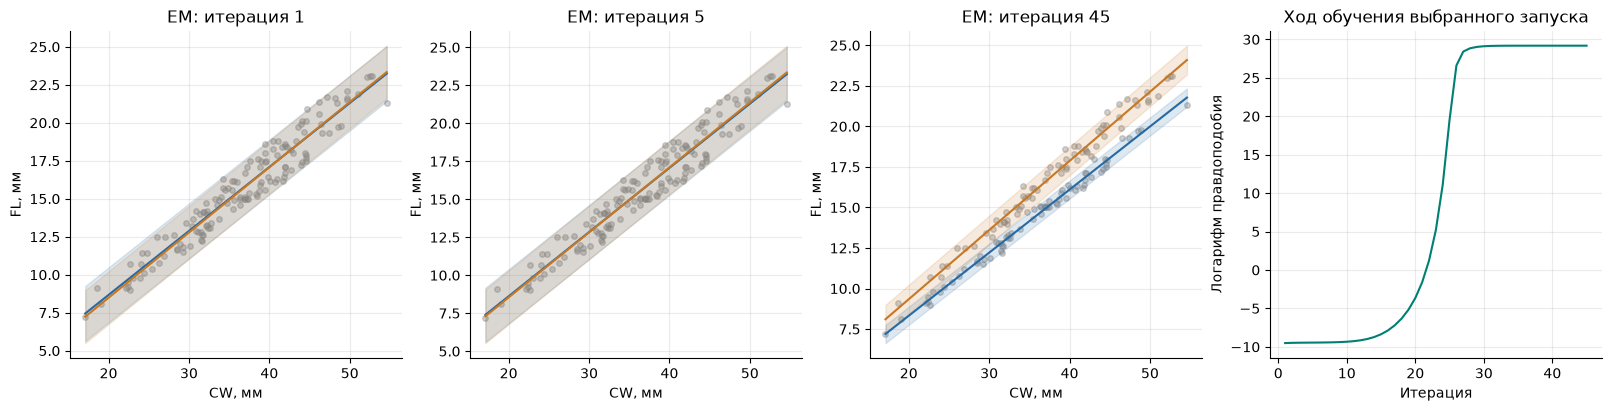

In [3]:
fig,axes=plt.subplots(1,4,figsize=(16,4),layout='constrained')
steps=[0,min(4,len(v2_cem['trace'])-1),len(v2_cem['trace'])-1]
for ax,step in zip(axes[:3],steps):
    beta,sigma=v2_em_raw(v2_cem,v2_cem['trace'][step]);ax.scatter(v2_ctr.CW,v2_ctr.FL,color='.55',s=16,alpha=.4)
    for k,cls in v2_cmap.items():
        mean=beta[k,0]+beta[k,1]*g;color=[BLUE,ORANGE][cls]
        ax.plot(g,mean,color=color);ax.fill_between(g,mean-1.96*sigma[k],mean+1.96*sigma[k],color=color,alpha=.15)
    ax.set(title=f'EM: итерация {step+1}',xlabel='CW, мм',ylabel='FL, мм');ax.grid()
axes[3].plot(np.arange(1,len(v2_cem['trace'])+1),[v['ll'] for v in v2_cem['trace']],color=GREEN)
axes[3].set(title='Ход обучения выбранного запуска',xlabel='Итерация',ylabel='Логарифм правдоподобия');axes[3].grid()
figure(fig,'15_crabs_em_training.png')

Выбранный запуск сошёлся за 45 итераций:

$$\begin{aligned}
B:&\quad \widehat{FL}=0.5497+0.38876\,CW,\quad \hat\sigma=0.2846;\\
O:&\quad \widehat{FL}=0.8200+0.42619\,CW,\quad \hat\sigma=0.4520.
\end{aligned}$$

Результат близок к регрессиям с известными метками. Здесь «без учителя» означает
неизвестную компоненту, а отклик $FL$ остаётся измеренным. Если скрыть ещё и
все обучающие значения $FL$, подогнать эту регрессию будет невозможно.
Обычная регрессия самой метки `B/O` также требует известных обучающих меток.

### 1.2. Подходит одной группе, обеим или ни одной

Для известных групп проверяем попадание в 95% прогнозный интервал своей прямой
и диапазон обучающих $CW$. Для EM используем ориентировочную полосу
$a_k+b_kCW\pm1.96\sigma_k$ и взвешенные квантили $CW$ 0,5–99,5% компоненты.
Последняя полоса учитывает остаточный разброс, но не всю неопределённость оценённых параметров.
Порог задан заранее; модель не обязана насильно назначать ближайшую группу.
Серый цвет означает «ни одной», фиолетовый — «обеим».

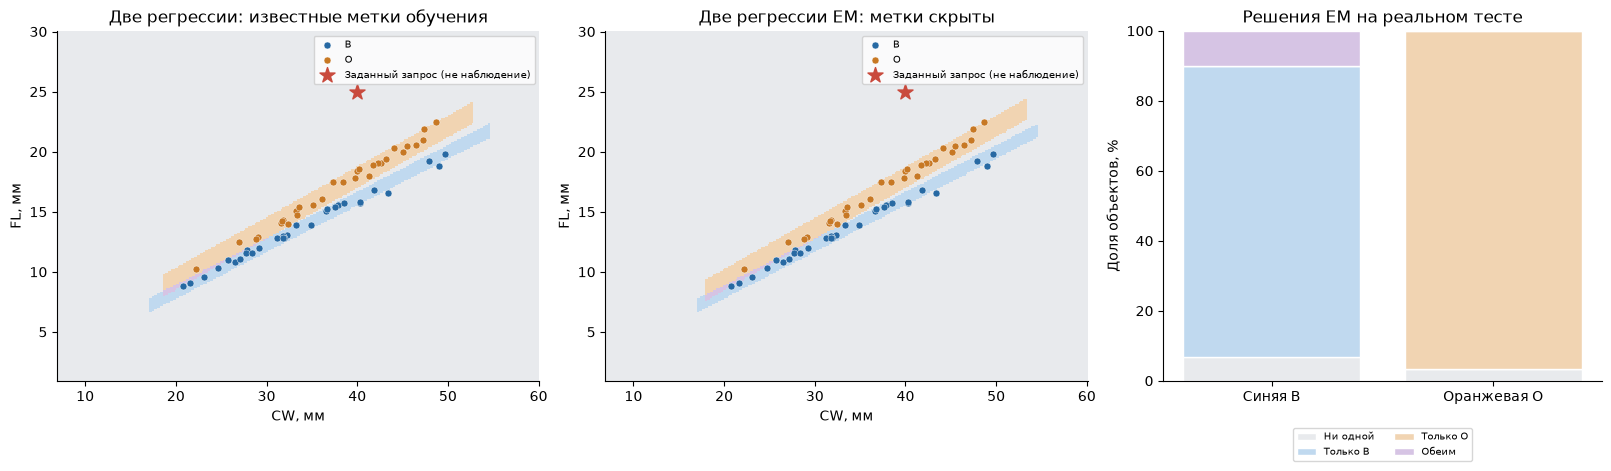

In [4]:
fig,axes=plt.subplots(1,3,figsize=(16,4.6),layout='constrained',gridspec_kw={'width_ratios':[1.1,1.1,1]})
xx,yy=np.meshgrid(np.linspace(7,60,300),np.linspace(1,30,220))
region_colors=['#E8EAED','#C0D9EF','#F1D4B2','#D6C4E4']
for ax,mode,title in zip(axes[:2],['known','em'],['Две регрессии: известные метки обучения','Две регрессии EM: метки скрыты']):
    decisions=v2_crab_compatible(xx.ravel(),yy.ravel(),mode).reshape(xx.shape)
    ax.pcolormesh(xx,yy,decisions,cmap=ListedColormap(region_colors),vmin=0,vmax=3,shading='auto',rasterized=True)
    for s,color in [('B',BLUE),('O',ORANGE)]:
        d=v2_cte.loc[v2_cte.sp.eq(s)];ax.scatter(d.CW,d.FL,color=color,s=25,label=s,edgecolor='white',linewidth=.3)
    ax.scatter([40],[25],color=RED,marker='*',s=130,label='Заданный запрос (не наблюдение)')
    ax.set(title=title,xlabel='CW, мм',ylabel='FL, мм');ax.legend(fontsize=7)
bottom=np.zeros(2)
for j,label in enumerate(['Ни одной','Только B','Только O','Обеим']):
    rates=np.array([v2_cstats['decision_counts'][s][j]/v2_cte.sp.eq(s).sum() for s in ['B','O']])*100
    axes[2].bar(['Синяя B','Оранжевая O'],rates,bottom=bottom,color=region_colors[j],label=label,edgecolor='white');bottom+=rates
axes[2].set(title='Решения EM на реальном тесте',ylabel='Доля объектов, %',ylim=(0,100));axes[2].legend(fontsize=7,loc='upper center',bbox_to_anchor=(.5,-.12),ncol=2)
figure(fig,'16_crabs_compatibility.png')

На 60 реальных тестовых объектах правило EM даёт **54 однозначных правильных
решения, 3 отказа и 3 неоднозначных решения**; однозначных ошибочных назначений нет.
Это отличается от принудительного выбора компоненты с максимальной плотностью.

Красная звезда $(CW,FL)=(40,25)$ — **заданный проверочный запрос**, а не измеренный
краб. Он не участвует в обучении или оценке качества и попадает вне обеих полос.
В датасете нет третьей формы для независимой проверки распознавания неизвестных
групп: возможность отказа показана, надёжность обнаружения любого нового класса не установлена.

### 1.3. Обычная классифицирующая регрессия и множественные регрессии

Сравниваем на одном тесте: ближайший центр (после масштабирования размеров);
МНК-регрессию бинарной метки по $CW,FL$ с порогом 0,5; две регрессии с известными
группами; смесь EM по одному и по двум предикторам.
МНК-оценка метки — численный классифицирующий балл, не калиброванная вероятность.
При классификации $FL$ является доступным измерением; при прогнозе $FL$ оно
не передаётся в предикторы. Справа — частные коэффициенты двухпредикторных моделей,
приведённые к одному SD признака внутри формы, с робастными 95% ДИ.

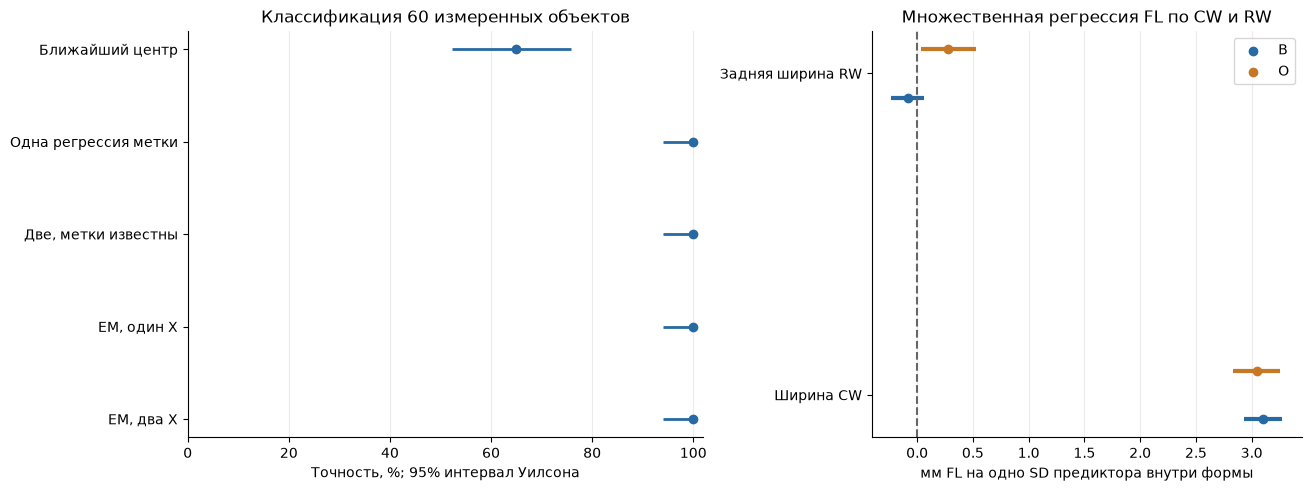

In [5]:
fig,axes=plt.subplots(1,2,figsize=(13,4.8),layout='constrained',gridspec_kw={'width_ratios':[1.2,1]})
names=list(v2_class_prediction)
for j,name in enumerate(names):
    item=v2_cstats['classification'][name];lo,hi=item['accuracy_ci'];axes[0].hlines(j,100*lo,100*hi,color=BLUE,lw=2);axes[0].scatter(item['accuracy']*100,j,color=BLUE)
axes[0].set(yticks=range(len(names)),yticklabels=names,xlabel='Точность, %; 95% интервал Уилсона',title='Классификация 60 измеренных объектов',xlim=(0,102));axes[0].invert_yaxis();axes[0].grid(axis='x')
for k,(s,color) in enumerate([('B',BLUE),('O',ORANGE)]):
    d=v2_ctr.loc[v2_ctr.sp.eq(s)];x=d[['CW','RW']];fit=ols((x-x.mean())/x.std(ddof=0),d.FL);ci=coefficient_ci(fit)
    for j in range(2):axes[1].hlines(j+(k-.5)*.15,*ci[j+1],color=color,lw=3);axes[1].scatter(fit['beta'][j+1],j+(k-.5)*.15,color=color,label=s if j==0 else None)
axes[1].axvline(0,color='.4',ls='--');axes[1].set(yticks=[0,1],yticklabels=['Ширина CW','Задняя ширина RW'],xlabel='мм FL на одно SD предиктора внутри формы',title='Множественная регрессия FL по CW и RW');axes[1].legend();axes[1].grid(axis='x')
figure(fig,'17_crabs_classification_multiple.png')

Ближайший центр распознал **39/60 (65%)**, остальные четыре подхода — **60/60**.
Для 60/60 интервал Уилсона примерно $[94.0\%;100\%]$: это результат малого
фиксированного теста, а не обещание безошибочности. **Преимущества двух регрессий
по точности над регрессией метки здесь нет**; их польза — описание двух зависимостей,
разных дисперсий, обучение при скрытых метках и правило совместимости с отказом.

Множественные модели в исходных единицах:

$$\begin{aligned}
B:&\quad \widehat{FL}=0.6932+0.39753\,CW-0.03730\,RW;\\
O:&\quad \widehat{FL}=0.7720+0.39028\,CW+0.10583\,RW.
\end{aligned}$$

Остаточные $s$ равны 0,2859 и 0,4271 мм. Добавление $RW$ слабо меняет разброс
у синей формы и несколько уменьшает его у оранжевой; это не обязательное
условие пригодности, а проверяемое свойство данных. Термины **«две регрессии»**
(две группы) и **«множественная регрессия»** (несколько предикторов) различаем;
в отчёте реализованы оба варианта.

## 2. UCI Yacht Hydrodynamics: нелинейность и вклад всех факторов

[UCI Yacht Hydrodynamics](https://archive.ics.uci.edu/dataset/243/yacht+hydrodynamics)
содержит 308 экспериментальных измерений сопротивления для 22 форм корпусов
парусных яхт. Это реальные лабораторные эксперименты Delft, не численная симуляция.
В файле каждая форма представлена на 14 скоростях. Пропусков и повторов строк нет,
отклик положителен.

Шесть безразмерных предикторов: продольное положение центра плавучести `lcb`,
призматический коэффициент `prismatic`, отношение длины к масштабу водоизмещения
`length_displacement`, ширины к осадке `beam_draught`, длины к ширине `length_beam`
и число Фруда $F$ (`froude`, характеристика скорости). Отклик $R$ — остаточное
сопротивление на единицу веса водоизмещения в шкале опубликованного файла.

**Разбиваем целыми корпусами:** 15 форм / 210 измерений на обучение,
7 форм / 98 измерений на тест. Внутри обучения — пять фолдов GroupKFold,
также без пересечения корпусов. Случайное деление отдельных строк давало бы
оценку на уже известных формах, а здесь проверяется перенос на новую форму.

Преобразуем отклик $T=\sqrt R$, а **каждый из шести предикторов** — в
B-сплайновый базис. Добавляем произведения базисов $F$ с базисами геометрии.
Ridge-регрессия линейна по коэффициентам в этом новом пространстве.
Варианты отклика $R/\sqrt R$, число узлов $F\in\{3,4,5\}$ и
$\alpha\in\{0.01,0.1,1,10\}$ сравниваются только по групповому CV обучения,
минимизируя MSE в исходной шкале $R$.

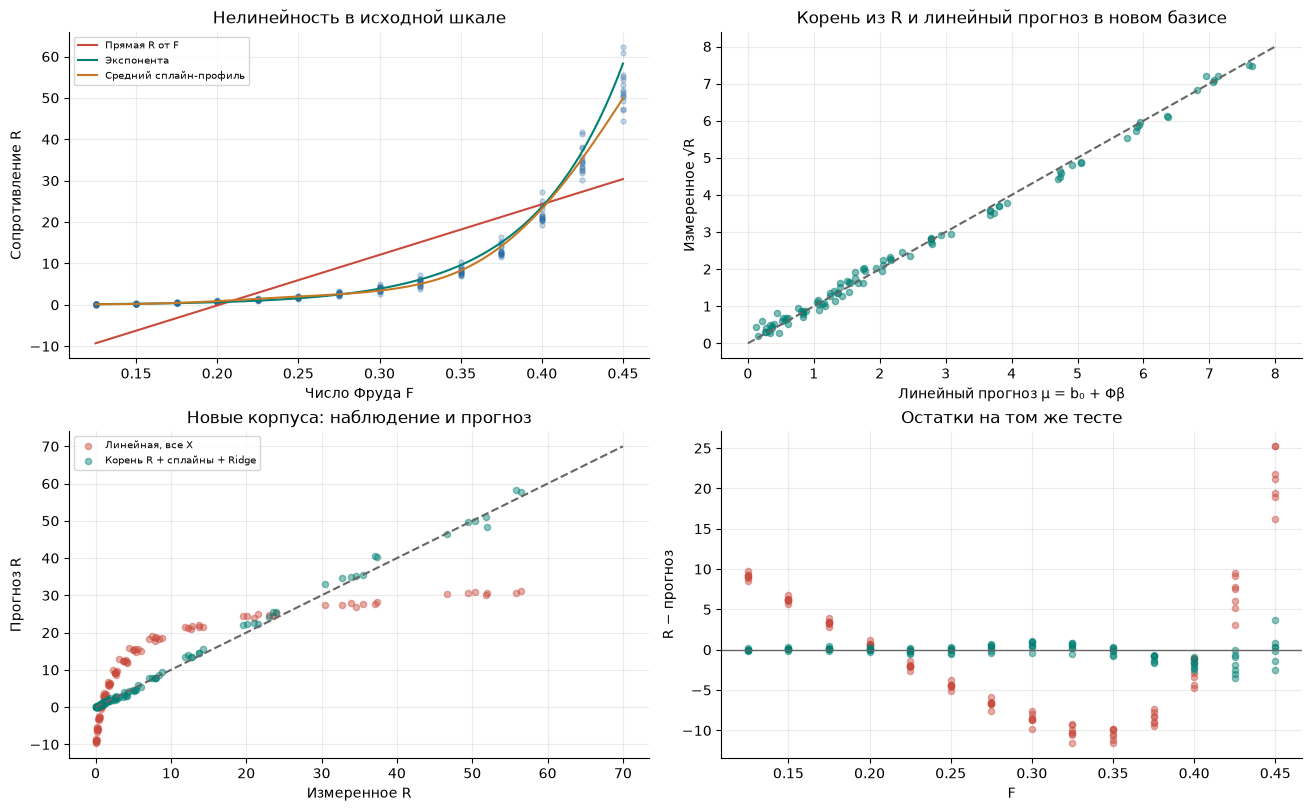

In [6]:
# Нелинейные признаки Yacht, линейная модель в новом пространстве и вклад факторов
v2_y_names=['lcb','prismatic','length_displacement','beam_draught','length_beam','froude']
v2_y_labels=['Центр плавучести','Призматический коэффициент','Длина / водоизмещение','Ширина / осадка','Длина / ширина','Число Фруда']
v2_yacht=pd.read_csv(BASE/'data/yacht_hydrodynamics.data',sep=r'\s+',names=v2_y_names+['resistance'])
assert v2_yacht.shape==(308,7) and not v2_yacht.isna().any().any()
assert not v2_yacht.duplicated().any() and v2_yacht.resistance.gt(0).all()
v2_yX=v2_yacht[v2_y_names].to_numpy();v2_yy=v2_yacht.resistance.to_numpy()
v2_yg=v2_yacht.groupby(v2_y_names[:5],sort=True).ngroup().to_numpy()
v2_ytr,v2_yte=next(GroupShuffleSplit(n_splits=1,test_size=.30,random_state=SEED).split(v2_yX,groups=v2_yg))
assert set(v2_yg[v2_ytr]).isdisjoint(v2_yg[v2_yte])
v2_yfolds=[(v2_ytr[a],v2_ytr[b]) for a,b in GroupKFold(n_splits=5).split(v2_ytr,groups=v2_yg[v2_ytr])]

class V2YachtBasis:
    def __init__(self,nf=5):self.nf=nf
    def fit(self,x):
        self.transforms=[];self.names=[];self.required=[]
        for j in range(6):
            s=SplineTransformer(n_knots=self.nf if j==5 else 2,degree=3 if j==5 else 2,
                                include_bias=False,extrapolation='linear' if j==5 else 'constant')
            s.fit(x[:,[j]]);self.transforms.append(s)
            self.names.extend([f'B_{v2_y_names[j]}_{k+1}' for k in range(s.n_features_out_)])
            self.required.extend([1<<j]*s.n_features_out_)
        nf=self.transforms[5].n_features_out_
        for k in range(nf):
            for j in range(5):
                for q in range(self.transforms[j].n_features_out_):
                    self.names.append(f'B_froude_{k+1}*B_{v2_y_names[j]}_{q+1}')
                    self.required.append((1<<5)|(1<<j))
        self.required=np.asarray(self.required)
        self.scaler=StandardScaler().fit(self.raw(x))
        return self
    def raw(self,x):
        blocks=[s.transform(x[:,[j]]) for j,s in enumerate(self.transforms)]
        interaction=(blocks[5][:,:,None]*np.column_stack(blocks[:5])[:,None,:]).reshape(len(x),-1)
        return np.column_stack(blocks+[interaction])
    def transform(self,x):return self.scaler.transform(self.raw(x))

class V2RidgeResponse:
    def __init__(self,alpha,target='sqrt'):
        self.alpha,self.target=alpha,target
    def fit(self,z,y):
        transformed=np.sqrt(y) if self.target=='sqrt' else y
        self.linear=Ridge(alpha=self.alpha,solver='svd').fit(z,transformed)
        self.coef_,self.intercept_=self.linear.coef_,self.linear.intercept_
        self.noise_var_=float(np.mean((transformed-self.linear.predict(z))**2)) if self.target=='sqrt' else 0.
        return self
    def predict_transformed(self,z):return self.linear.predict(z)
    def predict(self,z):
        mu=self.linear.predict(z)
        return mu**2+self.noise_var_ if self.target=='sqrt' else mu

# Параметры выбираются только на обучающих корпусах. Все варианты заданы явно.
v2_ygrid=[];v2_ycache={}
for nf in [3,4,5]:
    cache=[]
    for tr,va in v2_yfolds:
        basis=V2YachtBasis(nf).fit(v2_yX[tr])
        cache.append((tr,va,basis.transform(v2_yX[tr]),basis.transform(v2_yX[va])))
    v2_ycache[nf]=cache
    for alpha in [.01,.1,1.,10.]:
        for target in ['raw','sqrt']:
            mse=[];mae=[]
            for tr,va,zt,zv in cache:
                model=V2RidgeResponse(alpha,target).fit(zt,v2_yy[tr]);p=model.predict(zv)
                mse.append(mean_squared_error(v2_yy[va],p));mae.append(mean_absolute_error(v2_yy[va],p))
            v2_ygrid.append({'nf':nf,'alpha':alpha,'target':target,'cv_mse':float(np.mean(mse)),'cv_mae':float(np.mean(mae))})

v2_ychoice=min(v2_ygrid,key=lambda q:q['cv_mse']);v2_ynf=v2_ychoice['nf'];v2_yalpha=v2_ychoice['alpha'];v2_ytarget=v2_ychoice['target']
v2_ybasis=V2YachtBasis(v2_ynf).fit(v2_yX[v2_ytr]);v2_yZ=v2_ybasis.transform(v2_yX)
v2_yfull=V2RidgeResponse(v2_yalpha,v2_ytarget).fit(v2_yZ[v2_ytr],v2_yy[v2_ytr])

# Набор сравнений на одних и тех же корпусах, включая простой явный экспоненциальный закон.
def v2_y_models(tr,va,nf,alpha):
    xt,xv=v2_yX[tr],v2_yX[va];yt=v2_yy[tr]
    raw=ols(xt,yt);ex=ols(xt[:,5],np.log(yt));smear=np.exp(ex['error']).mean()
    basis=V2YachtBasis(nf).fit(xt);zt,zv=basis.transform(xt),basis.transform(xv)
    spline=V2RidgeResponse(alpha,v2_ytarget).fit(zt,yt)
    predictions={'Линейная, все X':predict(raw,xv),'Экспонента, только F':np.exp(predict(ex,xv[:,5]))*smear,
                 'Корень R + сплайны + Ridge':spline.predict(zv)}
    for name,cols in [('Лес, только F',[5]),('Лес, все X',list(range(6)))]:
        m=RandomForestRegressor(n_estimators=200,min_samples_leaf=2,random_state=SEED).fit(xt[:,cols],np.log(yt))
        sm=np.exp(np.log(yt)-m.predict(xt[:,cols])).mean()
        predictions[name]=np.exp(m.predict(xv[:,cols]))*sm
    return predictions

v2_ycv={name:[] for name in ['Линейная, все X','Экспонента, только F','Корень R + сплайны + Ridge','Лес, только F','Лес, все X']}
v2_y_oof=np.full(len(v2_yacht),np.nan);v2_y_oof_clean=np.full(len(v2_yacht),np.nan)

def v2_y_clean_mask(z,y,f,alpha,cutoff=3.5):
    fit=V2RidgeResponse(alpha,v2_ytarget).fit(z,y);e=y-fit.predict(z);keep=np.ones(len(y),bool)
    for speed in np.unique(f):
        loc=f==speed;median=np.median(e[loc]);scale=max(1.4826*np.median(np.abs(e[loc]-median)),1e-6)
        keep[loc]=np.abs(e[loc]-median)<=cutoff*scale
    return keep

for tr,va in v2_yfolds:
    preds=v2_y_models(tr,va,v2_ynf,v2_yalpha)
    for name,p in preds.items():v2_ycv[name].append({'mae':mean_absolute_error(v2_yy[va],p),'mse':mean_squared_error(v2_yy[va],p)})
    v2_y_oof[va]=preds['Корень R + сплайны + Ridge']
    basis=V2YachtBasis(v2_ynf).fit(v2_yX[tr]);zt,zv=basis.transform(v2_yX[tr]),basis.transform(v2_yX[va])
    keep=v2_y_clean_mask(zt,v2_yy[tr],v2_yX[tr,5],v2_yalpha)
    m=V2RidgeResponse(v2_yalpha,v2_ytarget).fit(zt[keep],v2_yy[tr][keep]);v2_y_oof_clean[va]=m.predict(zv)
v2_ytest_predictions=v2_y_models(v2_ytr,v2_yte,v2_ynf,v2_yalpha)
v2_ykeep=v2_y_clean_mask(v2_yZ[v2_ytr],v2_yy[v2_ytr],v2_yX[v2_ytr,5],v2_yalpha)
v2_yclean_indices=v2_ytr[v2_ykeep]
v2_yclean=V2RidgeResponse(v2_yalpha,v2_ytarget).fit(v2_yZ[v2_yclean_indices],v2_yy[v2_yclean_indices])
v2_ytest_clean=v2_yclean.predict(v2_yZ[v2_yte])
# Заранее показанные два порога: 3.5 — основной, 3.0 — чувствительность, не выбор по тесту.
v2_y_senskeep=v2_y_clean_mask(v2_yZ[v2_ytr],v2_yy[v2_ytr],v2_yX[v2_ytr,5],v2_yalpha,cutoff=3.0)
v2_y_sensindices=v2_ytr[v2_y_senskeep]
v2_y_sensmodel=V2RidgeResponse(v2_yalpha,v2_ytarget).fit(v2_yZ[v2_y_sensindices],v2_yy[v2_y_sensindices])
v2_y_senspred=v2_y_sensmodel.predict(v2_yZ[v2_yte])

# Точная Shapley-декомпозиция качества всех 2^6 подмножеств. Каждый раз модель переобучается.
v2_game_weights=np.zeros((64,6))
for j in range(6):
    for mask in range(64):
        if not mask&(1<<j):
            w=1/(6*math.comb(5,mask.bit_count()))
            v2_game_weights[mask,j]+=w;v2_game_weights[mask|(1<<j),j]-=w
v2_ygame={};v2_ygame_predictions={}
v2_ytest_groups=np.unique(v2_yg[v2_yte]);v2_yrng=np.random.default_rng(SEED)
v2_y_draws=v2_yrng.integers(0,len(v2_ytest_groups),size=(3000,len(v2_ytest_groups)))
for family in ['spline','forest']:
    predictions=[]
    for mask in range(64):
        cols=np.flatnonzero((v2_ybasis.required&mask)==v2_ybasis.required) if family=='spline' else [j for j in range(6) if mask&(1<<j)]
        if not len(cols):p=np.full(len(v2_yte),v2_yy[v2_ytr].mean())
        elif family=='spline':
            m=V2RidgeResponse(v2_yalpha,v2_ytarget).fit(v2_yZ[v2_ytr][:,cols],v2_yy[v2_ytr]);p=m.predict(v2_yZ[v2_yte][:,cols])
        else:
            m=RandomForestRegressor(n_estimators=200,min_samples_leaf=2,random_state=SEED).fit(v2_yX[v2_ytr][:,cols],np.log(v2_yy[v2_ytr]))
            smear=np.exp(np.log(v2_yy[v2_ytr])-m.predict(v2_yX[v2_ytr][:,cols])).mean()
            p=np.exp(m.predict(v2_yX[v2_yte][:,cols]))*smear
        predictions.append(p)
    pred=np.array(predictions).T;v2_ygame_predictions[family]=pred
    per_hull=np.array([((pred[v2_yg[v2_yte]==g]-v2_yy[v2_yte][v2_yg[v2_yte]==g,None])**2).mean(0) for g in v2_ytest_groups])
    loss=per_hull.mean(0);phi=loss@v2_game_weights;gain=loss[0]-loss[63]
    assert np.isclose(phi.sum(),gain)
    bootstrap_loss=per_hull[v2_y_draws].mean(1);bootstrap_phi=bootstrap_loss@v2_game_weights
    shares=100*phi/gain;share_samples=100*bootstrap_phi/(bootstrap_loss[:,0]-bootstrap_loss[:,63])[:,None]
    ci=np.quantile(share_samples,[.025,.975],axis=0).T
    ablation=np.array([loss[63^(1<<j)]-loss[63] for j in range(6)])
    v2_ygame[family]={'null_mse':float(loss[0]),'full_mse':float(loss[63]),'phi_mse':phi.tolist(),
                       'share_percent':shares.tolist(),'share_ci':ci.tolist(),'ablation_mse':ablation.tolist(),
                       'froude_only_mse':float(loss[32]),'geometry_added_relative_mse_gain':float((loss[32]-loss[63])/loss[32])}

# Блочный bootstrap обучающих корпусов для ДИ среднего профиля и одной фиксированной формы.
v2_ygridF=np.linspace(v2_yX[v2_ytr,5].min(),v2_yX[v2_ytr,5].max(),120)
v2_y_shapes=np.unique(v2_yX[v2_ytr,:5],axis=0)
v2_y_profile_X=np.column_stack([np.tile(v2_y_shapes,(len(v2_ygridF),1)),np.repeat(v2_ygridF,len(v2_y_shapes))])
v2_y_profile_Z=v2_ybasis.transform(v2_y_profile_X)
def v2_y_profile(model):return model.predict(v2_y_profile_Z).reshape(len(v2_ygridF),len(v2_y_shapes)).mean(1)
v2_y_hull_example=int(v2_ytest_groups[0]);v2_y_example_shape=v2_yX[np.flatnonzero(v2_yg==v2_y_hull_example)[0],:5]
v2_y_example_X=np.column_stack([np.tile(v2_y_example_shape,(len(v2_ygridF),1)),v2_ygridF])
v2_y_example_Z=v2_ybasis.transform(v2_y_example_X)
v2_y_profile_ci={};v2_y_example_ci={}
for label,ix in [('before',v2_ytr),('after',v2_yclean_indices),('cutoff3',v2_y_sensindices)]:
    rng=np.random.default_rng(SEED);hulls=np.unique(v2_yg[ix]);profile=[];example=[]
    for _ in range(300):
        selected=rng.choice(hulls,size=len(hulls),replace=True)
        bs=np.concatenate([ix[v2_yg[ix]==h] for h in selected])
        m=V2RidgeResponse(v2_yalpha,v2_ytarget).fit(v2_yZ[bs],v2_yy[bs])
        profile.append(v2_y_profile(m));example.append(m.predict(v2_y_example_Z))
    v2_y_profile_ci[label]=np.quantile(profile,[.025,.975],axis=0)
    v2_y_example_ci[label]=np.quantile(example,[.025,.975],axis=0)

# Эмпирический диапазон ошибок по скоростям: это не гарантированный conformal-интервал.
v2_y_levels=np.unique(v2_yX[v2_ytr,5]);v2_y_interval_stats={};v2_y_error_bands={}
for label,pred,oo in [('before',v2_ytest_predictions['Корень R + сплайны + Ridge'],v2_y_oof),('after',v2_ytest_clean,v2_y_oof_clean)]:
    errors=v2_yy[v2_ytr]-oo[v2_ytr]
    bands=np.array([np.quantile(errors[v2_yX[v2_ytr,5]==f],[.025,.975]) for f in v2_y_levels])
    low=np.maximum(0,pred+np.interp(v2_yX[v2_yte,5],v2_y_levels,bands[:,0]));high=np.maximum(0,pred+np.interp(v2_yX[v2_yte,5],v2_y_levels,bands[:,1]))
    v2_y_error_bands[label]=bands
    v2_y_interval_stats[label]={'coverage':float(((v2_yy[v2_yte]>=low)&(v2_yy[v2_yte]<=high)).mean()),'mean_width':float((high-low).mean())}
v2_y_expf=ols(v2_yX[v2_ytr,5],np.log(v2_yy[v2_ytr]));v2_y_exp_smear=float(np.exp(v2_y_expf['error']).mean())
v2_results['yacht']={
    'train':len(v2_ytr),'test':len(v2_yte),'train_hulls':15,'test_hulls':7,'selected':v2_ychoice,
    'basis_size':v2_yZ.shape[1],'response_residual_variance':v2_yfull.noise_var_,'grid':v2_ygrid,
    'scores':{name:{'cv_mae':float(np.mean([v['mae'] for v in v2_ycv[name]])),
                     'cv_rmse':float(np.sqrt(np.mean([v['mse'] for v in v2_ycv[name]]))),
                     'test_mae':float(mean_absolute_error(v2_yy[v2_yte],p)),
                     'test_rmse':float(np.sqrt(mean_squared_error(v2_yy[v2_yte],p))),
                     'test_r2':float(r2_score(v2_yy[v2_yte],p))} for name,p in v2_ytest_predictions.items()},
    'shapley':v2_ygame,'feature_names':v2_y_names,'feature_labels':v2_y_labels,
    'cleaning_removed':int((~v2_ykeep).sum()),'clean_test_mae':float(mean_absolute_error(v2_yy[v2_yte],v2_ytest_clean)),
    'clean_test_rmse':float(np.sqrt(mean_squared_error(v2_yy[v2_yte],v2_ytest_clean))),
    'cleaning_sensitivity':{'cutoff':3.0,'removed':int((~v2_y_senskeep).sum()),
                            'removed_zero_based_rows':v2_ytr[~v2_y_senskeep].tolist(),
                            'test_mae':float(mean_absolute_error(v2_yy[v2_yte],v2_y_senspred)),
                            'test_rmse':float(np.sqrt(mean_squared_error(v2_yy[v2_yte],v2_y_senspred)))},
    'negative_test_predictions':int((v2_ytest_predictions['Корень R + сплайны + Ridge']<0).sum()),
    'intervals':v2_y_interval_stats,'exp_equation':v2_y_expf['beta'].tolist(),'exp_smear':v2_y_exp_smear,
    'training_domain':{name:[float(v2_yX[v2_ytr,j].min()),float(v2_yX[v2_ytr,j].max())] for j,name in enumerate(v2_y_names)},
    'first_heldout_hull_example':v2_y_hull_example,
}
v2_coef_raw=v2_yfull.coef_/v2_ybasis.scaler.scale_
v2_intercept_raw=float(v2_yfull.intercept_-v2_ybasis.scaler.mean_@v2_coef_raw)
pd.DataFrame({'term':v2_ybasis.names,'coefficient':v2_coef_raw}).to_csv(OUT/'yacht_spline_coefficients.csv',index=False)
(OUT/'yacht_spline_equation.json').write_text(json.dumps({'intercept':v2_intercept_raw,'alpha':v2_yalpha,'response_transform':v2_ytarget,'response_residual_variance':v2_yfull.noise_var_,'feature_order':v2_y_names,
    'terms':dict(zip(v2_ybasis.names,map(float,v2_coef_raw))),
    'basis':[{ 'feature':v2_y_names[j],'degree':s.degree,'include_bias':False,'extrapolation':s.extrapolation,
               'knot_vector':s.bsplines_[0].t.tolist()} for j,s in enumerate(v2_ybasis.transforms)]},ensure_ascii=False,indent=2))
v2_results['yacht']['intercept_in_unscaled_basis']=v2_intercept_raw

fig,axes=plt.subplots(2,2,figsize=(13,8),layout='constrained')
axes[0,0].scatter(v2_yX[v2_ytr,5],v2_yy[v2_ytr],s=13,alpha=.25,color=BLUE)
rawF=ols(v2_yX[v2_ytr,5],v2_yy[v2_ytr]);axes[0,0].plot(v2_ygridF,predict(rawF,v2_ygridF),color=RED,label='Прямая R от F')
axes[0,0].plot(v2_ygridF,np.exp(predict(v2_y_expf,v2_ygridF))*v2_y_exp_smear,color=GREEN,label='Экспонента')
axes[0,0].plot(v2_ygridF,v2_y_profile(v2_yfull),color=ORANGE,label='Средний сплайн-профиль')
axes[0,0].set(title='Нелинейность в исходной шкале',xlabel='Число Фруда F',ylabel='Сопротивление R');axes[0,0].legend(fontsize=7)
mu=v2_yfull.predict_transformed(v2_yZ[v2_yte])
axes[0,1].scatter(mu,np.sqrt(v2_yy[v2_yte]),s=20,alpha=.5,color=GREEN)
axes[0,1].plot([0,8],[0,8],color='.4',ls='--')
axes[0,1].set(title='Корень из R и линейный прогноз в новом базисе',xlabel='Линейный прогноз μ = b₀ + Φβ',ylabel='Измеренное √R')
for name,color in [('Линейная, все X',RED),('Корень R + сплайны + Ridge',GREEN)]:
    p=v2_ytest_predictions[name];axes[1,0].scatter(v2_yy[v2_yte],p,s=20,alpha=.45,color=color,label=name)
    axes[1,1].scatter(v2_yX[v2_yte,5],v2_yy[v2_yte]-p,s=20,alpha=.45,color=color,label=name)
axes[1,0].plot([0,70],[0,70],color='.4',ls='--');axes[1,0].set(title='Новые корпуса: наблюдение и прогноз',xlabel='Измеренное R',ylabel='Прогноз R');axes[1,0].legend(fontsize=7)
axes[1,1].axhline(0,color='.4',lw=1);axes[1,1].set(title='Остатки на том же тесте',xlabel='F',ylabel='R − прогноз')
for ax in axes.ravel():ax.grid()
figure(fig,'18_yacht_transformed_linear_model.png')

### 2.1. Почему зависимость нелинейная и какое получилось уравнение

Одна прямая в исходных координатах систематически завышает малые и средние
сопротивления и занижает большие. На графике остатков видна кривизна.
Преобразование устраняет основную часть этого рисунка; вывод опирается также
на ошибку на **новых корпусах**, а не только на улучшение подгонки обучения.

На тесте MAE исходной линейной модели со всеми $X$ — **7,208**, после
преобразования — **0,625**; RMSE — **8,784 → 0,996**, $R^2$ — **0,657 → 0,9956**.
Групповая CV-MAE преобразованной модели — 0,776. CV использовано для выбора
настроек, поэтому это не полностью независимая оценка; отложенный тест отдельный.

Выбраны квадратный корень отклика, четыре узла кубического базиса $F$,
два узла квадратичного базиса каждого геометрического фактора, $\alpha=1$.
Всего 65 базисных членов с взаимодействиями. Уравнение в **немасштабированном
B-сплайновом базисе**:

$$\hat\mu(x)=5.0967104+\sum_{t=1}^{65}\beta_t\Phi_t(x),\qquad
\widehat{E[R\mid x]}\approx\hat\mu(x)^2+0.0111109.$$

Здесь $\hat\mu$ — линейная оценка $E[\sqrt R\mid x]$.
Прибавка — средний квадрат обучающих остатков в шкале $\sqrt R$:
$E[R\mid x]=E[\sqrt R\mid x]^2+\operatorname{Var}(\sqrt R\mid x)$.
Замена условной дисперсии одной константой приближённая, что ограничивает точность
поправки. Все 65 коэффициентов, определения базисов и узлы сохранены в
[CSV](outputs/yacht_spline_coefficients.csv) и [JSON уравнения](outputs/yacht_spline_equation.json),
поэтому формула воспроизводима, а не скрыта за названием модели.

Для простой демонстрации линеаризации достаточно также
$\ln R=-4.09588+18.03622F+\varepsilon$:
$\widehat{E[R\mid F]}\approx0.01741\exp(18.03622F)$ с поправкой smearing.
Но её тестовая MAE **1,201**, поэтому основной результат использует все параметры
и более гибкое преобразование. Экспонента — эмпирическое приближение на данном
интервале, не доказанный универсальный физический закон.

### 2.2. Какую долю качества даёт каждый параметр

Оцениваем вклад в **снижение MSE**, поскольку в регрессии нет естественного процента
«верно угаданных» значений без заданного допуска. Для каждого из $2^6=64$
подмножеств исходных факторов заново обучаем модель. Удаление фактора удаляет
также его сплайны и взаимодействия. Параметры семейства фиксированы по обучению;
каждому подмножеству отдельную настройку по тесту не подбираем.

Пусть $L(S)$ — тестовая MSE модели с факторами $S$, $L(\varnothing)$ — MSE
обучающей средней. Точный вклад Шепли усредняет прирост при всех порядках добавления:

$$\phi_j=\sum_{S\not\ni j}\frac{|S|!(5-|S|)!}{6!}
\left[L(S)-L(S\cup\{j\})\right],\qquad
q_j=100\,\frac{\phi_j}{L(\varnothing)-L(\mathrm{все})}.$$

Сумма $q_j$ равна 100%. Это разложение качества **переобученных моделей**,
а не объяснение одного прогноза и не причинное влияние.
Повторяем расчёт для сплайнов и случайного леса как проверки зависимости от модели.
Полосы — 95% процентильные интервалы 3000 bootstrap-перевыборок семи тестовых
корпусов; модели при этом фиксированы. Они показывают неопределённость состава
теста, не включают всё обучение и не являются поправкой на множественные проверки.

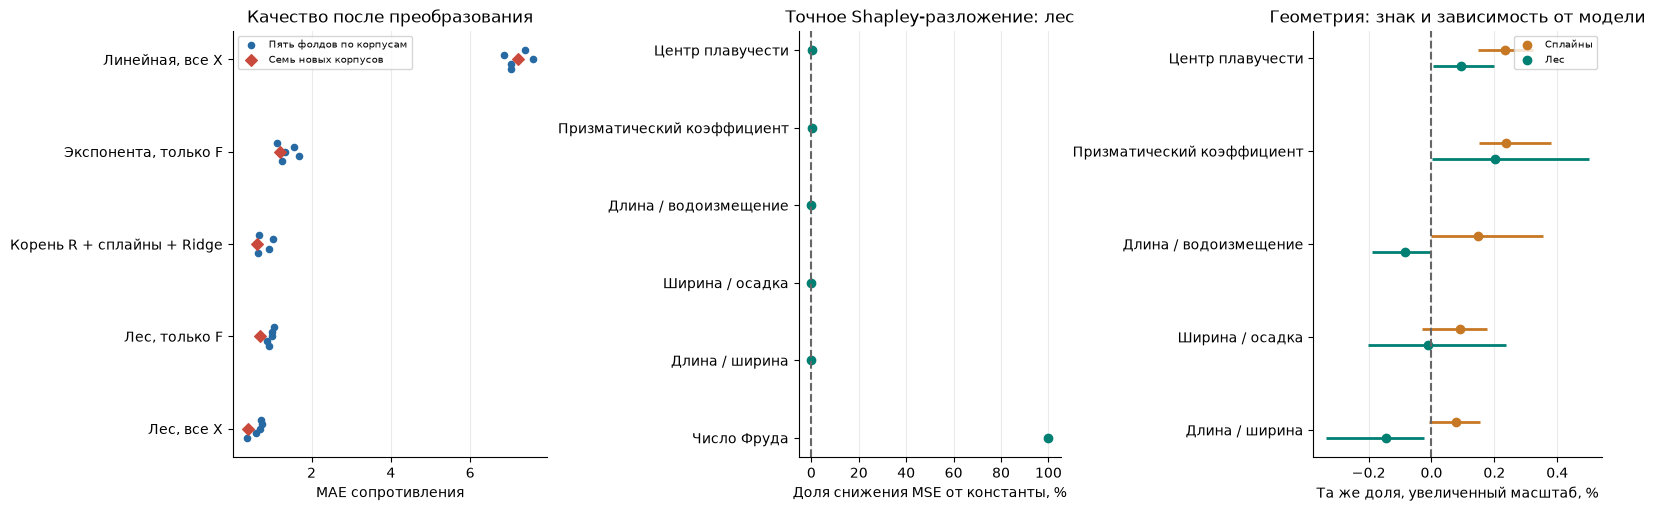

In [7]:
fig,axes=plt.subplots(1,3,figsize=(16,5),layout='constrained',gridspec_kw={'width_ratios':[1.2,1,1.1]})
for j,name in enumerate(v2_ycv):
    vals=[v['mae'] for v in v2_ycv[name]];axes[0].scatter(vals,j+np.linspace(-.1,.1,5),s=20,color=BLUE,label='Пять фолдов по корпусам' if j==0 else None)
    axes[0].scatter(v2_results['yacht']['scores'][name]['test_mae'],j,marker='D',s=35,color=RED,label='Семь новых корпусов' if j==0 else None)
axes[0].set(yticks=range(len(v2_ycv)),yticklabels=list(v2_ycv),xlabel='MAE сопротивления',title='Качество после преобразования');axes[0].invert_yaxis();axes[0].legend(fontsize=7)
game=v2_ygame['forest']
for j,label in enumerate(v2_y_labels):
    axes[1].hlines(j,*game['share_ci'][j],color=GREEN,lw=2);axes[1].scatter(game['share_percent'][j],j,color=GREEN)
axes[1].set(yticks=range(6),yticklabels=v2_y_labels,xlabel='Доля снижения MSE от константы, %',title='Точное Shapley-разложение: лес');axes[1].invert_yaxis();axes[1].axvline(0,color='.4',ls='--')
for j,label in enumerate(v2_y_labels[:5]):
    for k,(family,color) in enumerate([('spline',ORANGE),('forest',GREEN)]):
        game=v2_ygame[family];pos=j+(k-.5)*.17;axes[2].hlines(pos,*game['share_ci'][j],color=color,lw=2);axes[2].scatter(game['share_percent'][j],pos,color=color,label='Сплайны' if k==0 and j==0 else ('Лес' if j==0 else None))
axes[2].set(yticks=range(5),yticklabels=v2_y_labels[:5],xlabel='Та же доля, увеличенный масштаб, %',title='Геометрия: знак и зависимость от модели');axes[2].invert_yaxis();axes[2].axvline(0,color='.4',ls='--');axes[2].legend(fontsize=7)
for ax in axes:ax.grid(axis='x')
figure(fig,'19_yacht_feature_contributions.png')

**Для преобразованной линейной модели:** число Фруда даёт **99,213%** снижения MSE
относительно константы; геометрические факторы — 0,235% (`lcb`), 0,236%
(призматический коэффициент), 0,148% (длина / водоизмещение), 0,090%
(ширина / осадка), 0,077% (длина / ширина).
Среди геометрии первые два вклада почти одинаковы, и интервалы перекрываются:
объявлять один безусловно главным оснований нет. У трёх остальных нижние границы
интервалов около нуля или ниже. Это ограниченность текущей оценки, а не
доказательство отсутствия зависимости.

**Маленькая доля общего выигрыша не равна бесполезности.** Если сначала оставить
только $F$ в том же сплайновом семействе с фиксированными настройками, MSE равна
4,805; добавление геометрии уменьшает её до 0,993 — на **79,3% оставшейся ошибки**.
Знаменатели разные: доли Шепли считают выигрыш относительно MSE константы 224,967,
а последняя цифра — относительно ошибки модели с одним $F$.

В лесу доля $F$ — 99,940%, но геометрия вместе снижает оставшуюся MSE с 1,935
до 0,668 (**65,5%**); MAE — с 0,703 до 0,389. Некоторые индивидуальные доли леса
отрицательны: на этом тесте средний прирост от добавления этих факторов неблагоприятен.
При связанных признаках, 22 исходных корпусах и разных семействах моделей
доли могут менять знак и даже выходить за 0–100%; это не проценты физического
сопротивления. Вывод: **скорость доминирует, геометрия существенно уточняет прогноз**.

### 2.3. Выбросы и доверительные интервалы до/после

Проверяем только обучение; тест сохраняется целиком. Внутри каждого из 14 значений
$F$ считаем остатки $e=R-\hat R$, их медиану и робастный масштаб
$s_r=1.4826\,\operatorname{median}|e-\operatorname{median}(e)|$.
Основное правило — $|e-\operatorname{median}(e)|>3.5s_r$.
Проверка отдельно по скоростям учитывает изменение разброса $R$ с $F$.
Дополнительно показываем чувствительность к порогу $3s_r$, без выбора порога
по лучшему тестовому результату. Отмеченные строки — подозрительные по правилу,
а не подтверждённые ошибки лабораторного измерения.

Для среднего профиля сопротивления строим точечные 95% процентильные ДИ:
300 раз перевыбираем **целые обучающие корпуса**, переоцениваем коэффициенты
и усредняем прогнозы по исходным 15 обучающим формам при каждом $F$.
Узлы, $\alpha$ и выбранные для очистки строки фиксированы, поэтому эти интервалы
условны на процедуре выбора; 15 корпусов мало для строгой гарантии охвата.

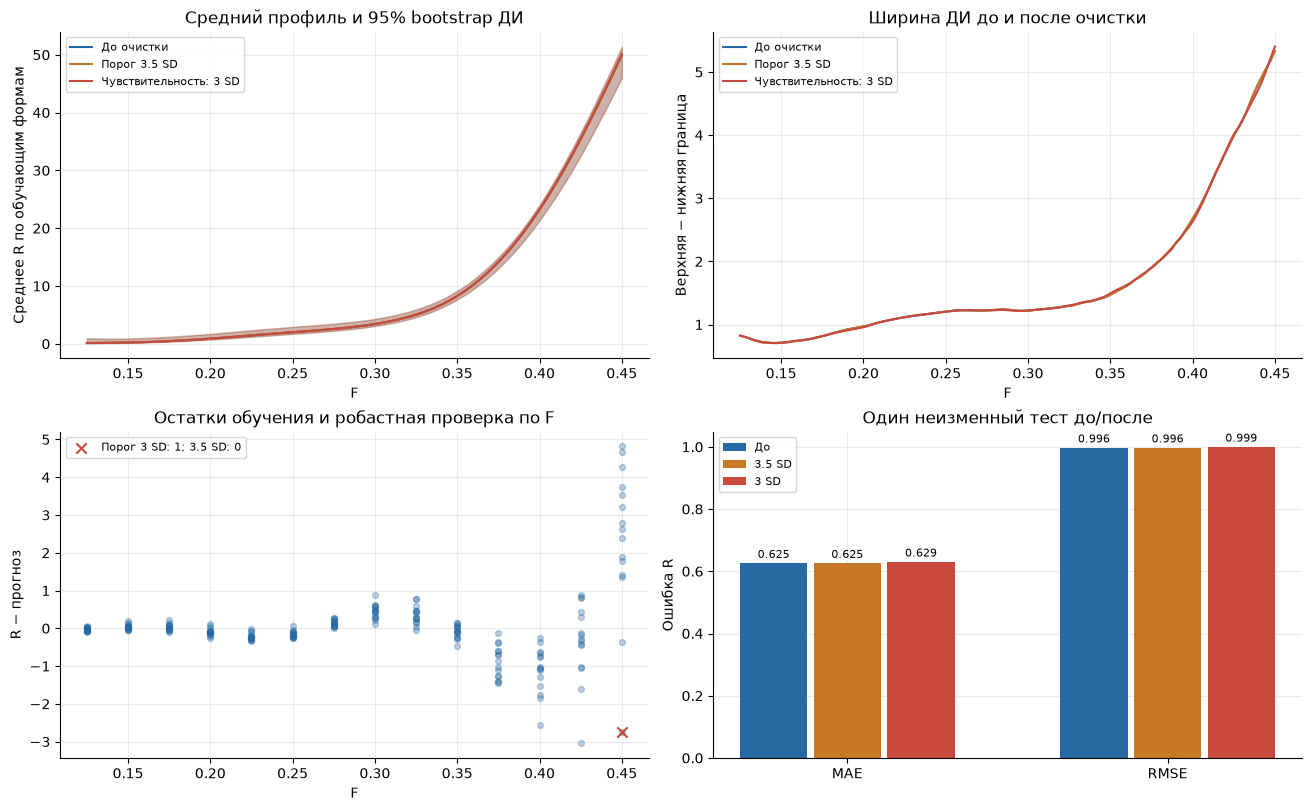

In [8]:
fig,axes=plt.subplots(2,2,figsize=(13,8),layout='constrained')
for label,model,color,text in [('before',v2_yfull,BLUE,'До очистки'),('after',v2_yclean,ORANGE,'Порог 3.5 SD'),('cutoff3',v2_y_sensmodel,RED,'Чувствительность: 3 SD')]:
    lo,hi=v2_y_profile_ci[label];axes[0,0].plot(v2_ygridF,v2_y_profile(model),color=color,label=text)
    axes[0,0].fill_between(v2_ygridF,lo,hi,color=color,alpha=.20)
    axes[0,1].plot(v2_ygridF,hi-lo,color=color,label=text)
axes[0,0].set(title='Средний профиль и 95% bootstrap ДИ',xlabel='F',ylabel='Среднее R по обучающим формам');axes[0,0].legend(fontsize=8)
axes[0,1].set(title='Ширина ДИ до и после очистки',xlabel='F',ylabel='Верхняя − нижняя граница');axes[0,1].legend(fontsize=8)
errors=v2_yy[v2_ytr]-v2_yfull.predict(v2_yZ[v2_ytr]);axes[1,0].scatter(v2_yX[v2_ytr,5],errors,color=BLUE,s=18,alpha=.3)
axes[1,0].scatter(v2_yX[v2_ytr[~v2_y_senskeep],5],errors[~v2_y_senskeep],color=RED,marker='x',s=55,label=f'Порог 3 SD: {(~v2_y_senskeep).sum()}; 3.5 SD: {(~v2_ykeep).sum()}')
axes[1,0].set(title='Остатки обучения и робастная проверка по F',xlabel='F',ylabel='R − прогноз');axes[1,0].legend(fontsize=8)
for j,(name,p,color) in enumerate([('До',v2_ytest_predictions['Корень R + сплайны + Ridge'],BLUE),('3.5 SD',v2_ytest_clean,ORANGE),('3 SD',v2_y_senspred,RED)]):
    mae=mean_absolute_error(v2_yy[v2_yte],p);rmse=np.sqrt(mean_squared_error(v2_yy[v2_yte],p));axes[1,1].bar(np.array([0,1])+j*.23,[mae,rmse],width=.21,color=color,label=name)
    for x,value in zip(np.array([0,1])+j*.23,[mae,rmse]):axes[1,1].annotate(f'{value:.3f}',(x,value),xytext=(0,4),textcoords='offset points',ha='center',fontsize=8)
axes[1,1].set(xticks=[.23,1.23],xticklabels=['MAE','RMSE'],title='Один неизменный тест до/после',ylabel='Ошибка R');axes[1,1].legend(fontsize=8)
for ax in axes.ravel():ax.grid()
figure(fig,'20_yacht_cleaning_confidence.png')

**Основной порог 3,5 SD:** отмечено **0/210 строк**, поэтому регрессия и ДИ
до/после совпадают, MAE = 0,625, RMSE = 0,996.
**Чувствительность, 3 SD:** отмечена одна строка; MAE = **0,629**, RMSE = **0,999**,
кривые и ДИ пересчитаны на графике. Улучшения тестового качества нет.
Оснований удалять реальные измерения ради более красивой регрессии не найдено.
Этот набор позволяет провести очистку и сравнение, но не обещает заметного
сужения интервалов: если преподавателю обязательно нужен пример с подтверждёнными
ошибочными измерениями, такое свойство здесь не установлено.

### 2.4. Область использования и неопределённость среднего прогноза

Слева взят первый по номеру отложенный корпус, без выбора по ошибке.
Полоса — точечный 95% bootstrap-ДИ **среднего** сопротивления для заданной
формы, полученный перевыборкой целых обучающих корпусов. Крестики — настоящие
измерения этого отложенного корпуса. Полоса среднего не является прогнозным
интервалом отдельного измерения: его разброс требует отдельного учёта.
Справа — абсолютная ошибка на всех семи отложенных корпусах по каждой скорости.

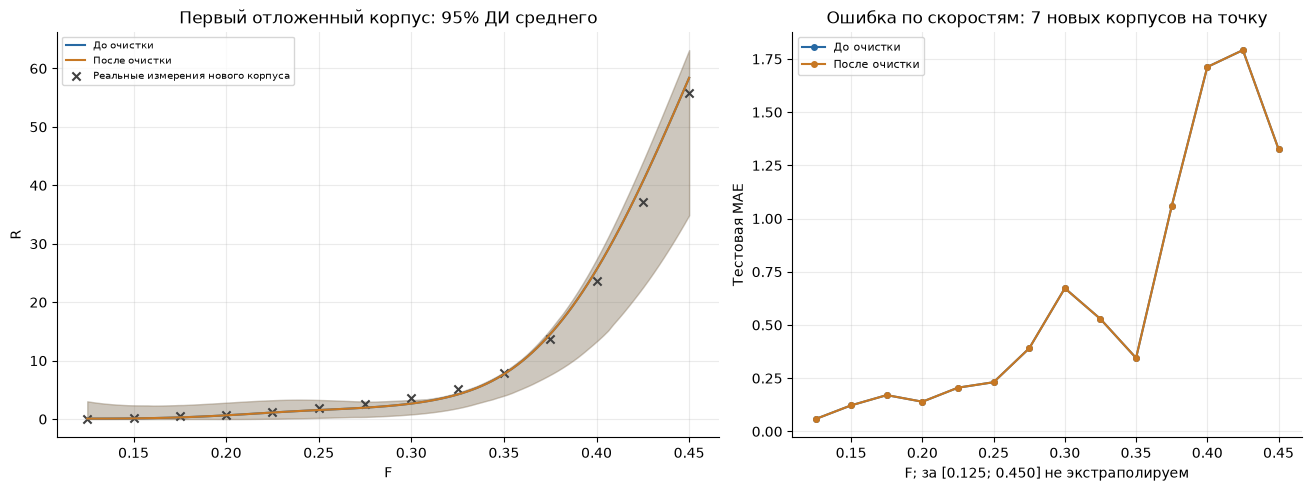

In [9]:
fig,axes=plt.subplots(1,2,figsize=(13,4.8),layout='constrained',gridspec_kw={'width_ratios':[1.3,1]})
exloc=v2_yte[v2_yg[v2_yte]==v2_y_hull_example]
for label,model,color,text in [('before',v2_yfull,BLUE,'До очистки'),('after',v2_yclean,ORANGE,'После очистки')]:
    p=model.predict(v2_y_example_Z)
    axes[0].fill_between(v2_ygridF,*v2_y_example_ci[label],color=color,alpha=.22)
    axes[0].plot(v2_ygridF,p,color=color,label=text)
axes[0].scatter(v2_yX[exloc,5],v2_yy[exloc],color='.25',marker='x',s=35,label='Реальные измерения нового корпуса')
axes[0].set(title='Первый отложенный корпус: 95% ДИ среднего',xlabel='F',ylabel='R');axes[0].legend(fontsize=7)
for label,p,color,text in [('before',v2_ytest_predictions['Корень R + сплайны + Ridge'],BLUE,'До очистки'),('after',v2_ytest_clean,ORANGE,'После очистки')]:
    mae=[np.abs(v2_yy[v2_yte][v2_yX[v2_yte,5]==f]-p[v2_yX[v2_yte,5]==f]).mean() for f in v2_y_levels]
    axes[1].plot(v2_y_levels,mae,'o-',color=color,ms=4,label=text)
axes[1].set(title='Ошибка по скоростям: 7 новых корпусов на точку',xlabel='F; за [0.125; 0.450] не экстраполируем',ylabel='Тестовая MAE');axes[1].legend(fontsize=8)
for ax in axes:ax.grid()
figure(fig,'21_yacht_prediction_domain.png')
results['selection_v2']=v2_results
_ = (OUT/'selection_v2_results.json').write_text(json.dumps(v2_results,ensure_ascii=False,indent=2))

Диапазон $F$ для использования формулы — **$[0.125;0.450]$** при близких к
обучающим формах корпуса. Диапазоны остальных факторов на обучении:
`lcb` $[-5;0]$, призматический коэффициент $[0.53;0.60]$,
длина / водоизмещение $[4.34;5.14]$, ширина / осадка $[2.81;5.35]$,
длина / ширина $[2.76;3.64]$. Произвольные комбинации значений внутри этих
одномерных границ могут не соответствовать изученным корпусам: границы не
заменяют проверку сходства геометрии. За областью измерений не экстраполируем.

Ошибка по $F$ показана справа, поэтому точность можно оценивать для нужной скорости,
а не объявлять весь интервал одинаково надёжным. При $F$ около 0,4–0,45 абсолютные
ошибки и неопределённость возрастают. Единой «допустимой» MAE без условия о
практическом допуске нет.

Для выбранной отложенной формы ДИ среднего при больших $F$ заметно шире,
чем ДИ профиля, усреднённого по обучающим формам. Значит, среднюю кривую
нельзя автоматически переносить на любой корпус с той же уверенностью.
Верхняя часть диапазона требует особенно осторожной оценки по геометрии
и допустимой ошибке; одно лишь попадание всех признаков в одномерные границы
недостаточно. Эти ДИ условны на выбранных базисах и настройках, а наблюдения
семи тестовых корпусов не устанавливают точный будущий 95% охват.

## 3. Текущий итог выбора

| Требование | Чем проверено |
|---|---|
| Две реальные группы и разный разброс | Crabs: две цветовые формы, $s=0.286/0.442$ мм |
| Одна регрессия, две регрессии, несколько предикторов | Crabs: общая прямая, регрессия метки, две отдельные, модели $FL\sim CW+RW$ |
| Скрыть ответы о группе и показать обучение | Crabs: EM, промежуточные прямые, кривая правдоподобия, тест после открытия меток |
| Совместимость с группами и отказ | Crabs: две полосы с ограничением по $CW$, четыре возможных решения |
| Нелинейная зависимость и её преобразование | Yacht: $\sqrt R$, базисы всех шести факторов, линейная по коэффициентам Ridge-модель |
| Уравнение и область применения | Yacht: полный набор коэффициентов и узлов, диапазоны факторов, ошибки по $F$ |
| Вклад остальных параметров | Yacht: точные доли Шепли для 64 подмножеств и уменьшение остаточной ошибки |
| Очистка и интервалы до/после | Yacht: два явных порога, 0/1 отмеченная строка, пересчитанные кривые, ДИ и тест |

**Рекомендуемая пара — Crabs + Yacht.** У первой есть две проверяемые регрессионные
полосы, у второй — убедительная нелинейность и содержательный анализ нескольких
признаков. Ограничения: у Crabs нет реального третьего класса для проверки
открытого распознавания; у Yacht не установлены ошибочные строки, которые
обязательно нужно удалять, и интервалы приближённые. Если под «множественной
регрессией» в формулировке подразумевались несколько прямых, представлены они;
если несколько предикторов — этот вариант также выполнен.

# Архив предыдущего выбора и прежнего критерия

**Далее — сохранённая предыдущая версия анализа.** Пингвины и Abalone были
исходными кандидатами; теперь оба обнаружены в списке преподавателя и не входят
в рекомендуемую пару. Прежняя проверка Yacht/Bluegill требовала именно бесполезности
дополнительных параметров; её отрицательный итог не относится к новому критерию
вклада признаков. Все исходные данные, формулы и графики оставлены для сравнения.
Актуальные рекомендации и результаты находятся выше.

## Архив 1. Palmer Penguins: что измерено и какие группы сравниваем

[Авторы набора Palmer Penguins](https://allisonhorst.github.io/palmerpenguins/)
публикуют измерения 344 пингвинов трёх видов с островов архипелага Палмера
за 2007–2009 годы. Размеры клюва и ласты даны в миллиметрах, масса — в граммах.
Локальный `data/penguins.csv` позволяет выполнить отчёт без доступа к сети.

Для двух регрессий используем Adelie и Gentoo. Chinstrap полностью оставляем
для проверки объектов вне этих двух групп. Это не обещает распознать любой
новый вид: чужой объект с подходящими измерениями может быть принят.
Пропуски в геометрии или массе удаляем; пропуск пола этому анализу не мешает.

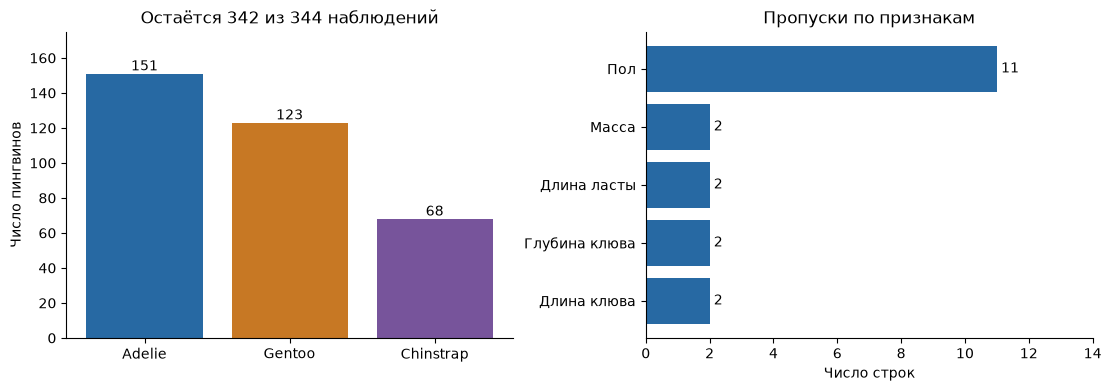

In [10]:
# Качество и охват данных пингвинов
p_raw = pd.read_csv(BASE / "data/penguins.csv")
geometry = ["bill_length_mm", "bill_depth_mm", "flipper_length_mm"]
penguins = p_raw.dropna(subset=geometry + ["body_mass_g"]).copy()
assert not penguins.duplicated().any()
assert penguins[geometry + ["body_mass_g"]].gt(0).all().all()
species_order = ["Adelie", "Gentoo", "Chinstrap"]
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), layout="constrained")
counts = penguins.species.value_counts().reindex(species_order)
bars = axes[0].bar(counts.index, counts, color=[COLORS[s] for s in counts.index])
axes[0].bar_label(bars)
axes[0].set(title=f"Остаётся {len(penguins)} из {len(p_raw)} наблюдений", ylabel="Число пингвинов", ylim=(0, 175))
missing = p_raw[geometry + ["body_mass_g", "sex"]].isna().sum()
bars = axes[1].barh(["Длина клюва", "Глубина клюва", "Длина ласты", "Масса", "Пол"], missing, color=BLUE)
axes[1].bar_label(bars, padding=3)
axes[1].set(title="Пропуски по признакам", xlabel="Число строк", xlim=(0, missing.max() + 3))
figure(fig, "01_penguins_quality.png")
results["penguin_counts"] = counts.to_dict()

### 1.1. Есть ли связь глубины и длины клюва у каждого вида?

Для каждого вида оцениваем d = a + bL + ε. Узкая полоса — 95% ДИ среднего
E[d|L], широкая — приближённый 95% прогнозный интервал отдельного пингвина.
Для ДИ коэффициентов и среднего используем HC3, устойчивую к неодинаковой
дисперсии; для прогнозного интервала предполагаем нормальные остатки с
постоянной дисперсией **внутри вида**. Это разные интервалы.

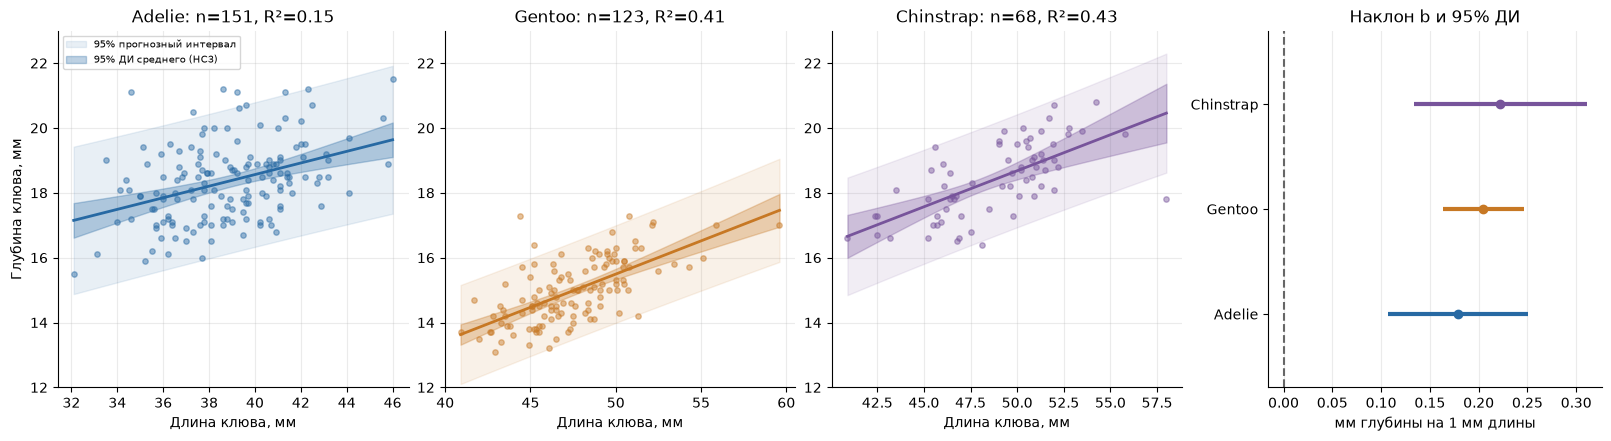

In [11]:
# Регрессии клюва и интервалы наклонов
bill_models = {}
fig, axes = plt.subplots(1, 4, figsize=(16, 4.3), layout="constrained", gridspec_kw={"width_ratios": [1, 1, 1, .95]})
for k, species in enumerate(species_order):
    part = penguins.loc[penguins.species.eq(species)]
    fit = ols(part.bill_length_mm, part.bill_depth_mm)
    bill_models[species] = fit
    grid = np.linspace(part.bill_length_mm.min(), part.bill_length_mm.max(), 160)
    mean_lo, mean_hi = interval(fit, grid)
    obs_lo, obs_hi = interval(fit, grid, observation=True)
    ax = axes[k]
    ax.fill_between(grid, obs_lo, obs_hi, color=COLORS[species], alpha=.10, label="95% прогнозный интервал")
    ax.fill_between(grid, mean_lo, mean_hi, color=COLORS[species], alpha=.30, label="95% ДИ среднего (HC3)")
    ax.scatter(part.bill_length_mm, part.bill_depth_mm, color=COLORS[species], alpha=.45, s=15)
    ax.plot(grid, predict(fit, grid), color=COLORS[species], lw=2)
    ax.set(title=f"{species}: n={len(part)}, R²={fit['r2']:.2f}", xlabel="Длина клюва, мм", ylim=(12, 23), ylabel="Глубина клюва, мм" if k == 0 else "")
    ax.grid()
    bounds = coefficient_ci(fit)[1]
    axes[3].hlines(k, *bounds, color=COLORS[species], lw=3)
    axes[3].scatter(fit["beta"][1], k, color=COLORS[species])
    results[f"bill_{species}"] = {"beta": fit["beta"].tolist(), "slope_ci": bounds.tolist(), "r2": fit["r2"], "sigma": np.sqrt(fit["mse"])}
axes[0].legend(fontsize=7, loc="upper left")
axes[3].axvline(0, color=".4", ls="--")
axes[3].set(title="Наклон b и 95% ДИ", yticks=range(3), yticklabels=species_order, xlabel="мм глубины на 1 мм длины", ylim=(-.7, 2.7))
axes[3].grid(axis="x")
figure(fig, "02_penguins_bill_regressions.png")

**Уравнения по всем доступным наблюдениям вида** (L и d в мм):

- **Adelie:** $\hat d=11.409+0.179L$, остаточное $s=1.123$ мм, $R^2=0.153$; 95% ДИ наклона [0.107; 0.251].
- **Gentoo:** $\hat d=5.251+0.205L$, остаточное $s=0.754$ мм, $R^2=0.414$; 95% ДИ наклона [0.164; 0.246].
- **Chinstrap:** $\hat d=7.569+0.222L$, остаточное $s=0.866$ мм, $R^2=0.427$; 95% ДИ наклона [0.134; 0.311].

Для отдельного наблюдения при нормальном шуме с постоянной дисперсией внутри вида:

$$d_{new}(L)\approx\hat d(L)\pm t_{n-2;0.975}\,s\sqrt{1+\frac1n+\frac{(L-\bar L)^2}{\sum_i(L_i-\bar L)^2}}.$$

Слагаемое 1 отвечает за естественный разброс отдельного пингвина. У доверительного интервала среднего его нет; HC3 дополнительно заменяет обычную оценку дисперсии среднего устойчивой. На краях диапазона неопределённость растёт.

Все три интервала наклона исключают ноль: на этих данных нельзя объявить
зависимость одного из видов «случайностью». При этом умеренное R² и широкие
прогнозные интервалы означают, что длина объясняет лишь часть разброса.
Вывод об отсутствии связи потребовал бы интервала, совместимого с нулём;
отсутствие статистической значимости само по себе не доказывало бы равенство нулю.

### 1.2. Масса как функция нескольких геометрических параметров

Проверяем предложение преподавателя: m = a + bF + cL + dD + ε, где F —
длина ласты, L — длина, D — глубина клюва. Слева показаны простые связи
массы с ластой; справа — частные коэффициенты **множественной** регрессии
по каждому виду. Для сравнения коэффициентов признаки справа стандартизованы
внутри вида, поэтому единица оси — граммы массы на одно SD признака.

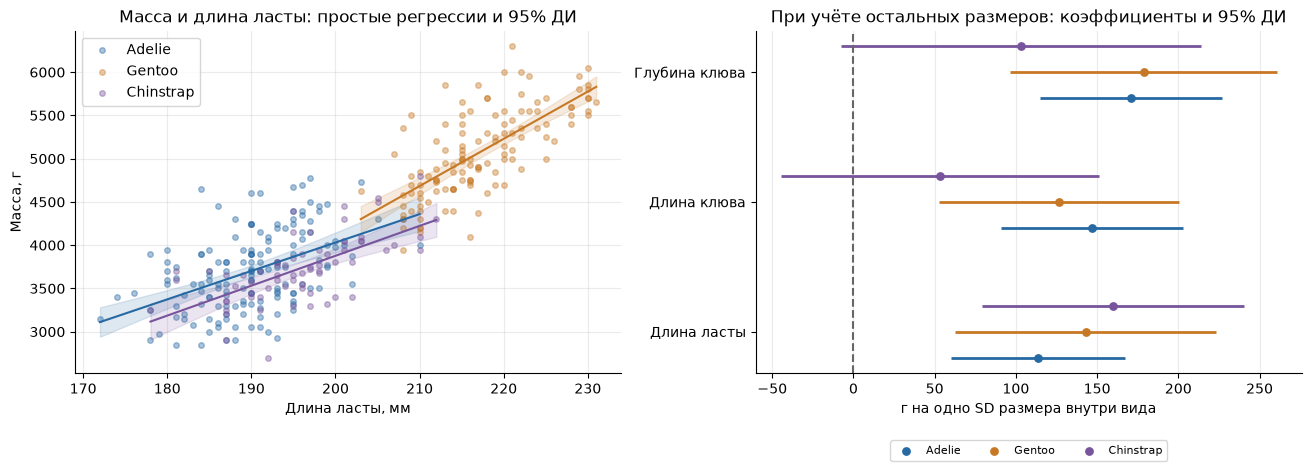

In [12]:
# Геометрия и масса: простая связь и частные эффекты
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained")
mass_models = {}
feature_names = ["Длина ласты", "Длина клюва", "Глубина клюва"]
for k, species in enumerate(species_order):
    part = penguins.loc[penguins.species.eq(species)]
    axes[0].scatter(part.flipper_length_mm, part.body_mass_g, color=COLORS[species], alpha=.4, s=16, label=species)
    simple = ols(part.flipper_length_mm, part.body_mass_g)
    grid = np.linspace(part.flipper_length_mm.min(), part.flipper_length_mm.max(), 100)
    lo, hi = interval(simple, grid)
    axes[0].plot(grid, predict(simple, grid), color=COLORS[species])
    axes[0].fill_between(grid, lo, hi, color=COLORS[species], alpha=.15)
    mass_x = part[["flipper_length_mm", "bill_length_mm", "bill_depth_mm"]]
    fit = ols(mass_x, part.body_mass_g)
    mass_models[species] = fit
    standardized = ols((mass_x - mass_x.mean()) / mass_x.std(ddof=0), part.body_mass_g)
    limits = coefficient_ci(standardized)
    for j in range(3):
        y = j + (k - 1) * .2
        axes[1].hlines(y, *limits[j + 1], color=COLORS[species], lw=2)
        axes[1].scatter(standardized["beta"][j + 1], y, color=COLORS[species], s=28, label=species if j == 0 else None)
    results[f"mass_{species}"] = {"beta": fit["beta"].tolist(), "r2": fit["r2"], "sigma": np.sqrt(fit["mse"]), "partial_ci": coefficient_ci(fit).tolist()}
axes[0].set(title="Масса и длина ласты: простые регрессии и 95% ДИ", xlabel="Длина ласты, мм", ylabel="Масса, г")
axes[0].legend(); axes[0].grid()
axes[1].axvline(0, color=".4", ls="--")
axes[1].set(title="При учёте остальных размеров: коэффициенты и 95% ДИ", yticks=range(3), yticklabels=feature_names, xlabel="г на одно SD размера внутри вида")
axes[1].legend(loc="upper center", bbox_to_anchor=(.5, -.18), ncol=3, fontsize=8)
axes[1].grid(axis="x")
figure(fig, "03_penguins_mass_geometry.png")

**Множественные уравнения массы**, F, L, D в мм, m в граммах:

- **Adelie:** $\hat m=-4341.3+17.42F+55.37L+140.89D$; $R^2=0.508$, остаточное $s=324.9$ г.
- **Gentoo:** $\hat m=-4426.5+22.12F+41.23L+182.81D$; $R^2=0.625$, остаточное $s=312.8$ г.
- **Chinstrap:** $\hat m=-3157.5+22.58F+16.04L+91.51D$; $R^2=0.504$, остаточное $s=277.0$ г.

У Chinstrap 95% ДИ частного коэффициента длины клюва [-13.53; 45.61] г/мм, глубины — [-6.83; 189.86] г/мм: оба включают ноль. Поэтому именно здесь есть пример неопределённого добавочного вклада клюва после учёта других размеров. Длина ласты имеет положительный частный коэффициент у всех трёх видов.

Это описательные уравнения в пределах измеренных размеров, а не причинные
эффекты. Сравнивать коэффициенты в исходных мм без учёта масштаба признаков
неудобно, поэтому на графике показана стандартизованная версия. Интервал,
пересекающий ноль, означает неопределённость **добавочного** вклада при
фиксированных остальных размерах, а не отсутствие простой корреляции с массой.

### 1.3. Одна регрессия, две регрессии и скрытые метки вида

Теперь возвращаемся к глубине клюва как y и длине как x — здесь особенно
наглядны две полосы и разный разброс. Adelie/Gentoo делим на обучение 70%
и тест 30% с сохранением долей видов. Chinstrap в обучение не попадает.

Сравниваем общую прямую, две прямые с известным видом и модель без меток вида.
Последняя — смесь двух двумерных нормальных распределений с полной
ковариацией, обучаемая EM. Условное распределение каждого компонента —
собственная линейная регрессия d|L,k ~ N(a_k+b_k L, σ²_k).
Вероятность компонента зависит от L, а принадлежность измеренного объекта —
от плотности пары (L,d), а не только от расстояния до центра.

Метки вида нужны только для разделения и последующей оценки. При подаче
данных в EM колонка species отсутствует. Для прогноза глубины на тесте
модель получает только длину; выбирать регрессию по известной тестовой
глубине и затем считать ошибку прогноза было бы некорректно.

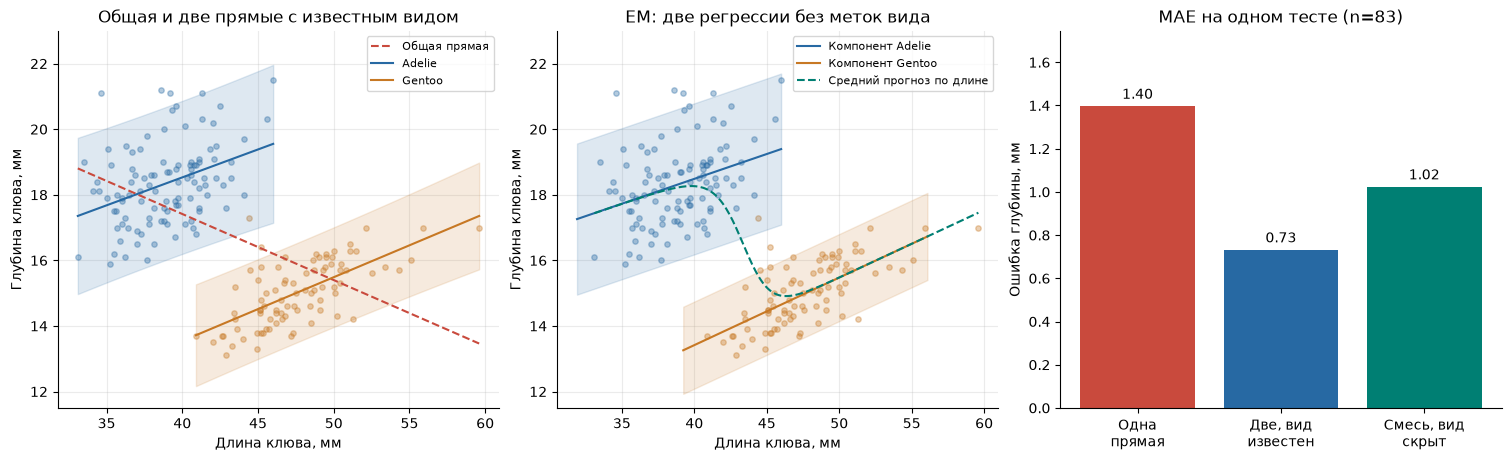

In [13]:
# Обучение одной и двух регрессий, EM без меток вида
known = penguins.loc[penguins.species.isin(["Adelie", "Gentoo"])].copy()
p_train, p_test = train_test_split(known, test_size=.30, stratify=known.species, random_state=SEED)
p_other = penguins.loc[penguins.species.eq("Chinstrap")]
pooled = ols(p_train.bill_length_mm, p_train.bill_depth_mm)
separate = {s: ols(d.bill_length_mm, d.bill_depth_mm) for s, d in p_train.groupby("species")}
pair = p_train[["bill_length_mm", "bill_depth_mm"]].to_numpy()
pair_mean, pair_sd = pair.mean(axis=0), pair.std(axis=0)
mixture = GaussianMixture(n_components=2, covariance_type="full", n_init=20, reg_covar=1e-5, random_state=SEED)
mixture.fit((pair - pair_mean) / pair_sd)  # Нет species и нет меток теста.
assert mixture.converged_
# Имена цветов присваиваем только после обучения, по положению полос.
component_order = np.argsort(mixture.means_[:, 1])[::-1]
components = {}
for species, k in zip(["Adelie", "Gentoo"], component_order):
    mu = mixture.means_[k] * pair_sd + pair_mean
    covariance = mixture.covariances_[k] * np.outer(pair_sd, pair_sd)
    slope = covariance[0, 1] / covariance[0, 0]
    components[species] = {
        "a": mu[1] - slope * mu[0], "b": slope,
        "sigma": np.sqrt(covariance[1, 1] - covariance[0, 1]**2 / covariance[0, 0]),
        "mx": mu[0], "vx": covariance[0, 0], "weight": mixture.weights_[k],
    }


def mixture_prediction(x):
    x = np.asarray(x)
    logs = np.column_stack([
        np.log(c["weight"]) - .5 * (np.log(2 * np.pi * c["vx"]) + (x - c["mx"])**2 / c["vx"])
        for c in components.values()
    ])
    weights = np.exp(logs - logsumexp(logs, axis=1, keepdims=True))
    means = np.column_stack([c["a"] + c["b"] * x for c in components.values()])
    return (weights * means).sum(axis=1)


pred_pooled = predict(pooled, p_test.bill_length_mm)
pred_oracle = np.array([predict(separate[row.species], [row.bill_length_mm])[0] for row in p_test.itertuples()])
pred_em = mixture_prediction(p_test.bill_length_mm)
predictions = {"Одна прямая": pred_pooled, "Две, вид известен": pred_oracle, "Смесь, вид скрыт": pred_em}
results["penguin_test"] = {name: {"mae": mean_absolute_error(p_test.bill_depth_mm, pred), "rmse": np.sqrt(mean_squared_error(p_test.bill_depth_mm, pred))} for name, pred in predictions.items()}
results["mixture"] = components
results["pooled_slope"] = pooled["beta"][1]
variance_p = levene(separate["Adelie"]["error"], separate["Gentoo"]["error"], center="median").pvalue
results["penguin_variance"] = {"p": variance_p, "sigmas": {s: np.sqrt(f["mse"]) for s, f in separate.items()}}
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), layout="constrained")
for ax in axes[:2]:
    for s, d in p_train.groupby("species"):
        ax.scatter(d.bill_length_mm, d.bill_depth_mm, s=15, color=COLORS[s], alpha=.35)
    ax.set(xlabel="Длина клюва, мм", ylabel="Глубина клюва, мм", ylim=(11.5, 23))
    ax.grid()
grid = np.linspace(p_train.bill_length_mm.min(), p_train.bill_length_mm.max(), 220)
axes[0].plot(grid, predict(pooled, grid), color=RED, ls="--", label="Общая прямая")
for s, fit in separate.items():
    part = p_train.loc[p_train.species.eq(s)]
    g = np.linspace(part.bill_length_mm.min(), part.bill_length_mm.max(), 130)
    low, high = interval(fit, g, observation=True)
    axes[0].fill_between(g, low, high, color=COLORS[s], alpha=.15)
    axes[0].plot(g, predict(fit, g), color=COLORS[s], label=s)
for s, c in components.items():
    g = np.linspace(c["mx"] - 2.58 * np.sqrt(c["vx"]), c["mx"] + 2.58 * np.sqrt(c["vx"]), 130)
    m = c["a"] + c["b"] * g
    axes[1].plot(g, m, color=COLORS[s], label=f"Компонент {s}")
    axes[1].fill_between(g, m - 1.96 * c["sigma"], m + 1.96 * c["sigma"], color=COLORS[s], alpha=.15)
axes[1].plot(grid, mixture_prediction(grid), color=GREEN, ls="--", label="Средний прогноз по длине")
axes[0].set_title("Общая и две прямые с известным видом")
axes[1].set_title("EM: две регрессии без меток вида")
axes[0].legend(fontsize=8); axes[1].legend(fontsize=8)
maes = [results["penguin_test"][n]["mae"] for n in predictions]
bars = axes[2].bar(range(3), maes, color=[RED, BLUE, GREEN])
axes[2].bar_label(bars, fmt="%.2f", padding=3)
axes[2].set(xticks=range(3), xticklabels=["Одна\nпрямая", "Две, вид\nизвестен", "Смесь, вид\nскрыт"], title=f"MAE на одном тесте (n={len(p_test)})", ylabel="Ошибка глубины, мм", ylim=(0, max(maes) * 1.25))
figure(fig, "04_penguins_two_regressions.png")

**Одна прямая смешивает группы:** общий наклон на обучении -0.202, хотя внутри каждого вида наклоны положительны. Это пример изменения знака связи при объединении разных групп, а не отрицательная связь внутри вида.

На обучении остаточные SD Adelie и Gentoo равны 1.170 и 0.758 мм. Диагностический тест Левена по остаткам: p=0.00025; он согласуется с различием разбросов, при этом остатки сами оценены по данным.

На одном тесте из 83 пингвинов MAE:

- Одна прямая: **1.397 мм**, RMSE 1.651 мм.
- Две, вид известен: **0.732 мм**, RMSE 0.905 мм.
- Смесь, вид скрыт: **1.024 мм**, RMSE 1.310 мм.

**Уравнения, найденные EM без меток вида:**

- Полоса Adelie: $d\mid L,k\sim N(12.423+0.152L,\ 1.175^2)$.
- Полоса Gentoo: $d\mid L,k\sim N(5.177+0.206L,\ 0.677^2)$.

Для EM полоса ±1,96σ показывает оценённый внутригрупповой шум, без
неопределённости параметров; у регрессий с известным видом показан t-интервал
с учётом параметров. Поэтому ширину этих полос нельзя сравнивать как
одинаково точные доверительные интервалы. Две прямые с известным видом —
ориентир при дополнительной информации; смесь на тесте этой информации не имеет.

### 1.4. «Подходит первому, второму, обоим или ни одному»

Для известных групп объект совместим с регрессией, если глубина внутри
95% прогнозного интервала и длина внутри обучающего диапазона вида.
Для EM используем |d−a_k−b_k L| ≤ 1,96σ_k и
(L−μ_L,k)²/v_L,k ≤ χ²(1;0,99): ограничиваем также область по длине.
У EM это приближённое правило совместимости, а не калиброванная вероятность
принадлежности виду. Отклонение по двум критериям не имеет ровно 5% уровня.
Обе модели могут вернуть неоднозначность или отказ. Метки Chinstrap никогда
не используются для обучения или настройки границ.

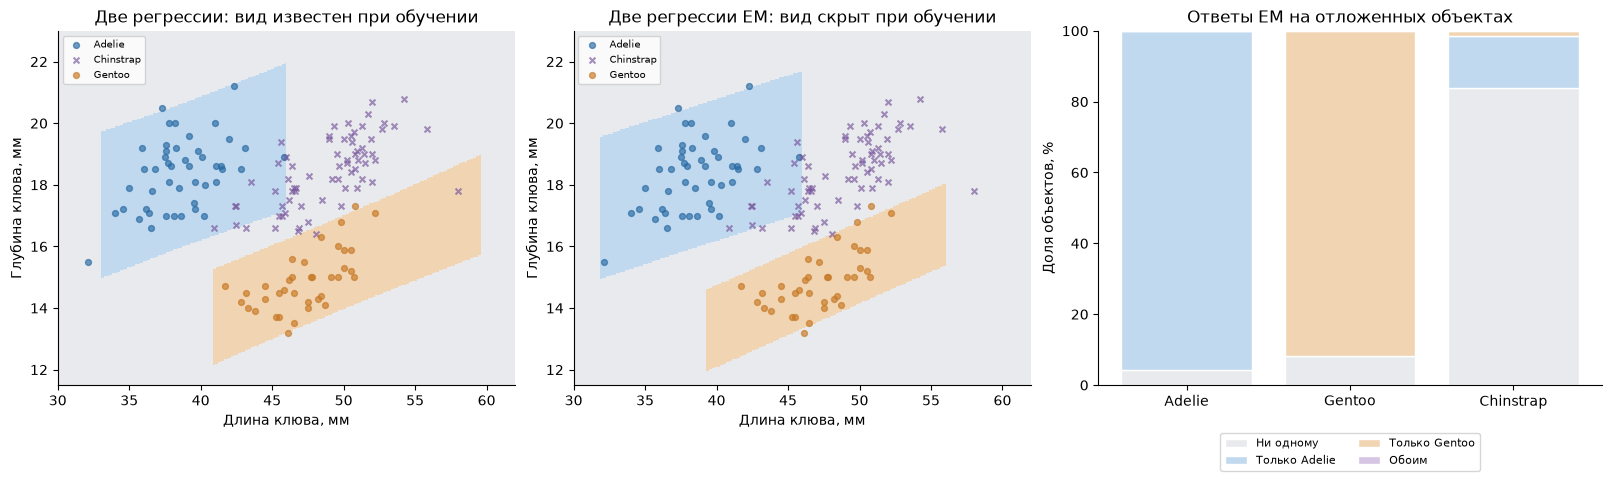

In [14]:
# Области совместимости и проверка третьего вида

def compatible(x, y, method):
    x, y = np.asarray(x), np.asarray(y)
    accepted = []
    for s in ["Adelie", "Gentoo"]:
        if method == "supervised":
            lo, hi = interval(separate[s], x, observation=True)
            p = p_train.loc[p_train.species.eq(s), "bill_length_mm"]
            inside = (x >= p.min()) & (x <= p.max()) & (y >= lo) & (y <= hi)
        else:
            c = components[s]
            inside = ((x - c["mx"])**2 / c["vx"] <= chi2.ppf(.99, 1)) & (np.abs(y - c["a"] - c["b"] * x) <= 1.96 * c["sigma"])
        accepted.append(inside)
    return accepted[0].astype(int) + 2 * accepted[1].astype(int)


xx, yy = np.meshgrid(np.linspace(30, 62, 300), np.linspace(11.5, 23, 240))
region_colors = ["#E8EAED", "#C0D9EF", "#F1D4B2", "#D6C4E4"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.7), layout="constrained", gridspec_kw={"width_ratios": [1, 1, 1.1]})
for ax, method, title in zip(axes[:2], ["supervised", "em"], ["Две регрессии: вид известен при обучении", "Две регрессии EM: вид скрыт при обучении"]):
    regions = compatible(xx.ravel(), yy.ravel(), method).reshape(xx.shape)
    ax.pcolormesh(xx, yy, regions, cmap=ListedColormap(region_colors), vmin=0, vmax=3, shading="auto", rasterized=True)
    for s, part in pd.concat([p_test, p_other]).groupby("species"):
        ax.scatter(part.bill_length_mm, part.bill_depth_mm, color=COLORS[s], marker="x" if s == "Chinstrap" else "o", s=18, alpha=.65, label=s)
    ax.set(title=title, xlabel="Длина клюва, мм", ylabel="Глубина клюва, мм", xlim=(30, 62), ylim=(11.5, 23))
    ax.legend(fontsize=7, loc="upper left")
# Четыре исхода по фактическим видам; только тест известных видов плюс весь третий вид.
evaluation = pd.concat([p_test, p_other])
decisions = compatible(evaluation.bill_length_mm, evaluation.bill_depth_mm, "em")
decision_counts = pd.crosstab(evaluation.species.to_numpy(), decisions).reindex(index=species_order, columns=range(4), fill_value=0)
decision_rates = decision_counts.div(decision_counts.sum(axis=1), axis=0)
bottom = np.zeros(3)
for j, name in enumerate(["Ни одному", "Только Adelie", "Только Gentoo", "Обоим"]):
    axes[2].bar(species_order, decision_rates[j] * 100, bottom=bottom, color=region_colors[j], edgecolor="white", label=name)
    bottom += decision_rates[j].to_numpy() * 100
axes[2].set(title="Ответы EM на отложенных объектах", ylabel="Доля объектов, %", ylim=(0, 100))
axes[2].legend(fontsize=8, loc="upper center", bbox_to_anchor=(.5, -.12), ncol=2)
figure(fig, "05_penguins_compatibility.png")
results["penguin_decisions"] = {s: decision_counts.loc[s].tolist() for s in species_order}

**Проверка правила EM.** Из 83 тестовых Adelie/Gentoo однозначно принят правильной полосой 78, отклонено 5. Из 68 Chinstrap отклонено 57 (83.8%), остальные 11 совместимы с одной из известных полос. Здесь не возникло ответов «обоим», но правило сохраняет такую возможность при пересечении областей. Отказ и ошибка класса учитываются отдельно.

**Пригодность первого датасета.** Набор подходит: две отдельные регрессии
имеют разный разброс, а правило допускает отказ и неоднозначность. Одна
прямая усредняет разные группы. Чужой вид частично пересекается с известными,
поэтому стопроцентное отвержение Chinstrap по двум размерам недостижимо.
Для задачи множественной регрессии дополнительно доступны три геометрических
признака массы. Корреляция и правила совместимости не доказывают биологическую
принадлежность нового пингвина и не заменяют внешнюю проверку на других колониях.

## Архив 2. Abalone: нелинейная зависимость полной массы от размера

[UCI Abalone](https://archive.ics.uci.edu/dataset/1/abalone) содержит 4177
наблюдений морских ушек: пол/категория I, три размера, полная масса, массы
частей и кольца. Исходная цель UCI — возраст; здесь **цель переопределена**
как полная масса W. Rings не используем как целевую переменную.
Значения оставляем в опубликованном масштабе файла: формулы ниже относятся
именно к нему, единицы автоматически не пересчитываем.

Геометрическая гипотеза: W ≈ aL^b; при сходной форме объём и масса растут
примерно как куб линейного размера. Логарифм даёт ln W = ln a + b ln L + ε.
Показатель b оцениваем, а не фиксируем равным трём.

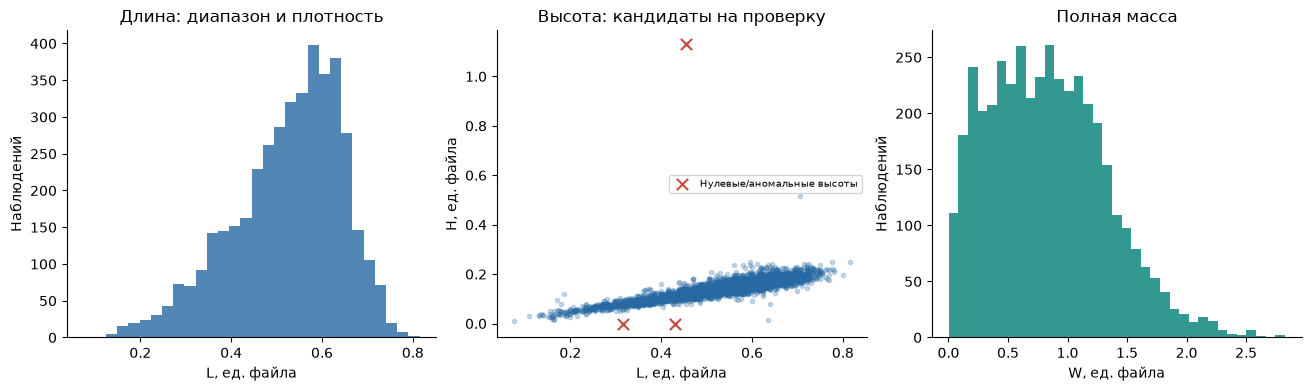

In [15]:
# Качество Abalone и единое разбиение
columns = ["sex", "length", "diameter", "height", "whole_weight", "shucked_weight", "viscera_weight", "shell_weight", "rings"]
a_raw = pd.read_csv(BASE / "data/abalone.data", names=columns)
assert not a_raw.isna().any().any() and not a_raw.duplicated().any()
positive = a_raw[["length", "diameter", "height", "whole_weight"]].gt(0).all(axis=1)
abalone = a_raw.loc[positive].copy()
a_train, a_test = train_test_split(abalone, test_size=.25, random_state=SEED)
assert set(a_train.index).isdisjoint(a_test.index)
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), layout="constrained")
axes[0].hist(a_raw.length, bins=30, color=BLUE, alpha=.8)
axes[0].set(title="Длина: диапазон и плотность", xlabel="L, ед. файла", ylabel="Наблюдений")
axes[1].scatter(a_raw.length, a_raw.height, s=9, alpha=.25, color=BLUE)
flags = a_raw.height.le(0) | a_raw.height.gt(a_raw.length)
axes[1].scatter(a_raw.loc[flags, "length"], a_raw.loc[flags, "height"], color=RED, marker="x", s=65, label="Нулевые/аномальные высоты")
axes[1].set(title="Высота: кандидаты на проверку", xlabel="L, ед. файла", ylabel="H, ед. файла")
axes[1].legend(fontsize=7)
axes[2].hist(a_raw.whole_weight, bins=35, color=GREEN, alpha=.8)
axes[2].set(title="Полная масса", xlabel="W, ед. файла", ylabel="Наблюдений")
figure(fig, "06_abalone_quality.png")
results["abalone_counts"] = {"raw": len(a_raw), "nonpositive": int((~positive).sum()), "train": len(a_train), "test": len(a_test)}

Два наблюдения с нулевой высотой исключены до общего разбиения, потому
что логарифм высоты не определён. Это правило области определения, а не
удаление по величине ошибки. Аномальная высота 1,13 пока сохранена:
статистический выброс не объявляем доказанной ошибкой измерения.
Все дальнейшие сравнения используют одни и те же отложенные строки.

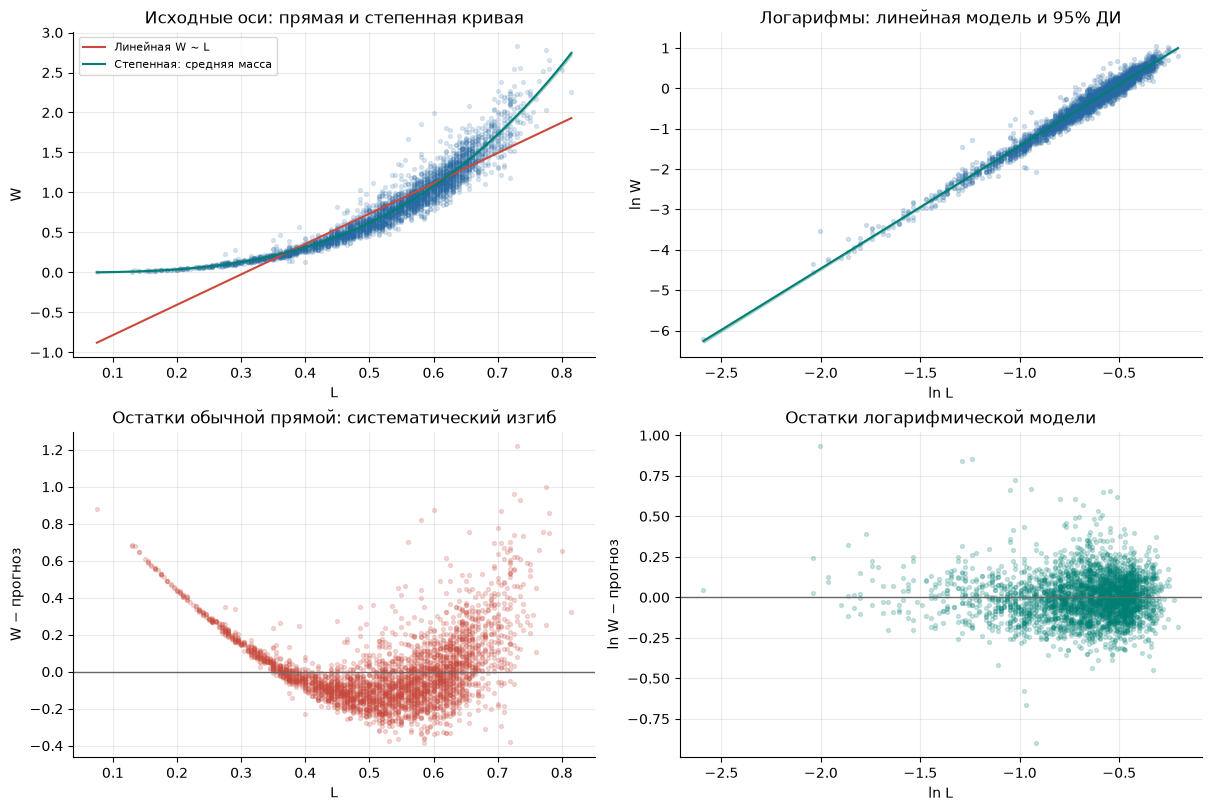

In [16]:
# Модели массы: преобразования, дополнительные признаки и очистка
specifications = {
    "Линейная L": (["length"], False, False),
    "Линейная L,D,H": (["length", "diameter", "height"], False, False),
    "Степенная L": (["length"], True, False),
    "Степенная L,D,H": (["length", "diameter", "height"], True, False),
    "L,D,H + пол": (["length", "diameter", "height"], True, True),
    "L,D,H + пол + кольца": (["length", "diameter", "height", "rings"], True, True),
    "L,D,H + массы частей": (["length", "diameter", "height", "shucked_weight", "viscera_weight", "shell_weight"], True, False),
}


def abalone_x(frame, specification):
    names, logged, sex = specifications[specification]
    values = frame[names].to_numpy(dtype=float)
    if logged:
        values = np.log(values)
    if sex:
        values = np.column_stack([values, frame.sex.eq("F"), frame.sex.eq("I")])
    return values


def fit_abalone(frame, specification):
    logged = specifications[specification][1]
    y = np.log(frame.whole_weight) if logged else frame.whole_weight
    fit = ols(abalone_x(frame, specification), y)
    # Поправка smearing оценивается только по обучающим остаткам.
    fit["smear"] = float(np.exp(fit["error"]).mean()) if logged else 1.
    fit["spec"] = specification
    return fit


def predict_mass(fit, frame, mean=True):
    value = predict(fit, abalone_x(frame, fit["spec"]))
    if specifications[fit["spec"]][1]:
        return np.exp(value) * (fit["smear"] if mean else 1.)
    return value


def clean_training(frame):
    # Робастные правила оцениваются заново на каждом обучающем фолде.
    initial = fit_abalone(frame, "Степенная L")
    e = initial["error"]
    center = np.median(e)
    scale = max(1.4826 * np.median(np.abs(e - center)), 1e-9)
    ratio = np.log(frame.height / frame.length).to_numpy()
    ratio_center = np.median(ratio)
    ratio_scale = max(1.4826 * np.median(np.abs(ratio - ratio_center)), 1e-9)
    bad_residual = np.abs(e - center) > 3.5 * scale
    bad_geometry = (np.abs(ratio - ratio_center) > 4.5 * ratio_scale) | frame.height.gt(frame.length).to_numpy()
    keep = ~(bad_residual | bad_geometry)
    return frame.loc[keep], {"removed": int((~keep).sum()), "residual": int(bad_residual.sum()), "geometry": int(bad_geometry.sum())}


clean_train, clean_stats = clean_training(a_train)
results["cleaning"] = clean_stats
raw_fits = {name: fit_abalone(a_train, name) for name in specifications}
clean_fits = {name: fit_abalone(clean_train, name) for name in specifications}
linear_fit = raw_fits["Линейная L"]
power_fit = raw_fits["Степенная L"]
length_grid = np.linspace(a_train.length.min(), a_train.length.max(), 250)
grid_frame = pd.DataFrame({"length": length_grid})
log_lo, log_hi = interval(power_fit, np.log(length_grid))
fig, axes = plt.subplots(2, 2, figsize=(12, 8), layout="constrained")
axes[0, 0].scatter(a_train.length, a_train.whole_weight, s=8, alpha=.15, color=BLUE)
axes[0, 0].plot(length_grid, predict_mass(linear_fit, grid_frame), color=RED, label="Линейная W ~ L")
axes[0, 0].plot(length_grid, predict_mass(power_fit, grid_frame), color=GREEN, label="Степенная: средняя масса")
axes[0, 0].fill_between(length_grid, np.exp(log_lo) * power_fit["smear"], np.exp(log_hi) * power_fit["smear"], color=GREEN, alpha=.25)
axes[0, 0].set(title="Исходные оси: прямая и степенная кривая", xlabel="L", ylabel="W")
axes[0, 0].legend(fontsize=8)
axes[0, 1].scatter(np.log(a_train.length), np.log(a_train.whole_weight), s=8, alpha=.18, color=BLUE)
axes[0, 1].plot(np.log(length_grid), predict(power_fit, np.log(length_grid)), color=GREEN)
axes[0, 1].fill_between(np.log(length_grid), log_lo, log_hi, color=GREEN, alpha=.25)
axes[0, 1].set(title="Логарифмы: линейная модель и 95% ДИ", xlabel="ln L", ylabel="ln W")
axes[1, 0].scatter(a_train.length, linear_fit["error"], color=RED, s=8, alpha=.2)
axes[1, 0].set(title="Остатки обычной прямой: систематический изгиб", xlabel="L", ylabel="W − прогноз")
axes[1, 1].scatter(np.log(a_train.length), power_fit["error"], color=GREEN, s=8, alpha=.2)
axes[1, 1].set(title="Остатки логарифмической модели", xlabel="ln L", ylabel="ln W − прогноз")
for ax in axes[1]: ax.axhline(0, color=".4", lw=1)
for ax in axes.ravel(): ax.grid()
figure(fig, "07_abalone_linearization.png")
results["power_raw"] = {"beta": power_fit["beta"].tolist(), "ci": coefficient_ci(power_fit).tolist(), "smear": power_fit["smear"], "sigma": np.sqrt(power_fit["mse"])}

**До очистки:** $\ln W=1.6214+3.0425\ln L+\varepsilon$, то есть геометрическое среднее $W\approx 5.0601L^{3.0425}$. 95% ДИ показателя степени: [3.0214; 3.0637], он далеко от 1; зависимость близка к кубической, но b не фиксировано равным 3. Поправка среднего smearing=1.01002.

На одинаковом тесте MAE обычной прямой 0.1396, степенной модели 0.0879; $R^2$ растёт с 0.852 до 0.931. Это подтверждает пользу преобразования и вне обучения.

**Почему зависимость нелинейна.** В исходных координатах у обычной прямой
остаётся изгиб остатков, тогда как ln W от ln L ближе к прямой. Проверяем
это также ошибкой на одинаковых отложенных объектах. Преобразование осей
само по себе не является доказательством качества прогноза.
exp(a+b ln L) описывает геометрическое среднее, а при симметричном шуме
логарифмов — медиану W|L. Для прогноза арифметической средней массы
умножаем на smearing = mean(exp(ε)) обучающей выборки. При выраженной
неодинаковой дисперсии логарифмов такая общая поправка лишь приближённая.

### 2.1. Помогают ли остальные параметры?

Сравниваем модели на пяти фолдах обучения и на одном фиксированном тесте.
В каждом фолде все коэффициенты и smearing оцениваются заново. Здесь пока
нет очистки статистических выбросов, чтобы выделить эффект признаков.
По тестовым строкам bootstrap оценивает 95% ДИ **парной разности MAE**
при последовательном добавлении признаков. Положительная разность
MAE(база)−MAE(расширенная) означает улучшение; это четыре отдельных исследовательских
сравнения, без заявления об одновременном 95% уровне.

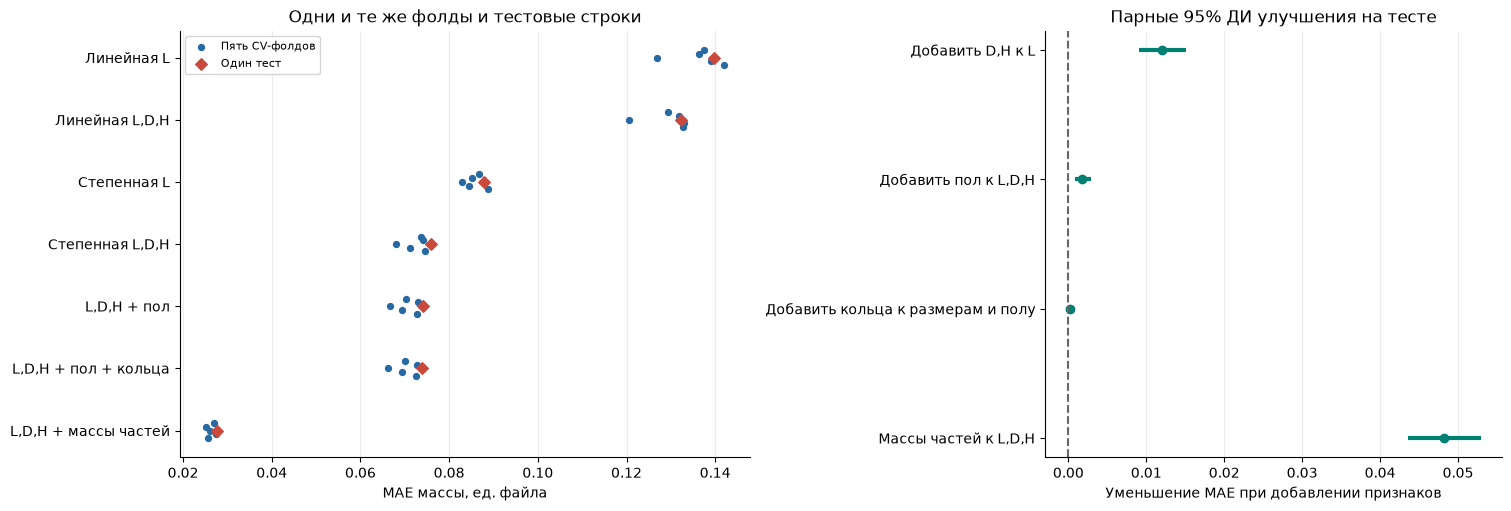

In [17]:
# Сравнение признаков: CV и парные разности ошибок на тесте
folds = KFold(n_splits=5, shuffle=True, random_state=SEED)
cv_errors = {name: [] for name in specifications}
for tr, va in folds.split(a_train):
    for name in specifications:
        fitted = fit_abalone(a_train.iloc[tr], name)
        cv_errors[name].append(mean_absolute_error(a_train.iloc[va].whole_weight, predict_mass(fitted, a_train.iloc[va])))
test_errors = {}
for name, fit in raw_fits.items():
    pred = predict_mass(fit, a_test)
    test_errors[name] = np.abs(a_test.whole_weight.to_numpy() - pred)
    results.setdefault("abalone_scores", {})[name] = {
        "mae": test_errors[name].mean(), "rmse": np.sqrt(np.mean((a_test.whole_weight.to_numpy() - pred)**2)),
        "r2": r2_score(a_test.whole_weight, pred), "cv_mae": np.mean(cv_errors[name]),
    }
fig, axes = plt.subplots(1, 2, figsize=(15, 5), layout="constrained", gridspec_kw={"width_ratios": [1.25, 1]})
positions = np.arange(len(specifications))
for j, name in enumerate(specifications):
    axes[0].scatter(cv_errors[name], j + np.linspace(-.12, .12, 5), color=BLUE, s=18, label="Пять CV-фолдов" if j == 0 else None)
    axes[0].scatter(test_errors[name].mean(), j, color=RED, marker="D", s=35, label="Один тест" if j == 0 else None)
axes[0].set(yticks=positions, yticklabels=list(specifications), xlabel="MAE массы, ед. файла", title="Одни и те же фолды и тестовые строки")
axes[0].invert_yaxis(); axes[0].legend(fontsize=8); axes[0].grid(axis="x")
feature_comparisons = [
    ("Степенная L", "Степенная L,D,H"),
    ("Степенная L,D,H", "L,D,H + пол"),
    ("L,D,H + пол", "L,D,H + пол + кольца"),
    ("Степенная L,D,H", "L,D,H + массы частей"),
]
rng = np.random.default_rng(SEED)
indices = rng.integers(0, len(a_test), size=(2000, len(a_test)))
paired = {}
for j, (baseline, name) in enumerate(feature_comparisons):
    difference = test_errors[baseline] - test_errors[name]
    low, high = np.quantile(difference[indices].mean(axis=1), [.025, .975])
    paired[name] = {"baseline": baseline, "delta": difference.mean(), "lo": low, "hi": high}
    axes[1].hlines(j, low, high, color=GREEN, lw=3)
    axes[1].scatter(difference.mean(), j, color=GREEN)
axes[1].axvline(0, color=".4", ls="--")
axes[1].set(yticks=range(4), yticklabels=["Добавить D,H к L", "Добавить пол к L,D,H", "Добавить кольца к размерам и полу", "Массы частей к L,D,H"], xlabel="Уменьшение MAE при добавлении признаков", title="Парные 95% ДИ улучшения на тесте")
axes[1].invert_yaxis(); axes[1].grid(axis="x")
figure(fig, "08_abalone_extra_features.png")
results["paired_improvement"] = paired

**Проверка вместо предположения о бесполезности признаков.** Добавление диаметра и высоты уменьшает тестовую MAE с 0.0879 до 0.0759; 95% ДИ улучшения [0.0090; 0.0151] исключает ноль. Пол даёт ещё небольшое улучшение: [0.0008; 0.0028]. Поэтому утверждение «остальные параметры не помогают» для этого набора неверно.

**Пример признака без убедительного добавочного выигрыша:** кольца после размеров и пола уменьшают MAE лишь на 0.00018, 95% ДИ [-0.00032; 0.00069] содержит ноль. Это отсутствие установленного улучшения на данном тесте, а не доказанная бесполезность колец вообще. Массы частей дают MAE 0.0277, но требуют другой доступной информации.

Массы мяса, внутренностей и раковины особенно информативны, потому что
относятся к частям той же полной массы. Это другая практическая постановка:
для прогноза массы неповреждённого объекта они обычно недоступны заранее.
Кольца тоже требуют отдельного измерения. Эти признаки не скрываем, но
отделяем их от прогноза только по внешним размерам. Дополнительные размеры
могут помогать и при пригодности длины для демонстрации линеаризации.

### 2.2. Очистка выбросов: сравнение без подмены теста

На обучении отмечаем: остаток ln W ~ ln L дальше 3,5 робастных SD от медианы;
ln(H/L) дальше 4,5 робастных SD; H > L. Робастное SD = 1,4826×MAD.
Пороги выбраны как диагностическое правило, а не по минимальной ошибке теста.
Кандидаты могут быть настоящими необычными животными: очистка — анализ
чувствительности. На тесте не удаляем строки по их массе или ошибке.

Чтобы сравнение CV было честным, внутри каждого фолда пороги очистки
вычисляются только на его обучающей части. Доверительные интервалы после
очистки условны относительно выбранных строк и не учитывают неопределённость
самого решения об удалении. HC3 оценивает неопределённость среднего профиля;
прогнозный интервал дополнительно предполагает одинаковый нормальный шум в ln W.

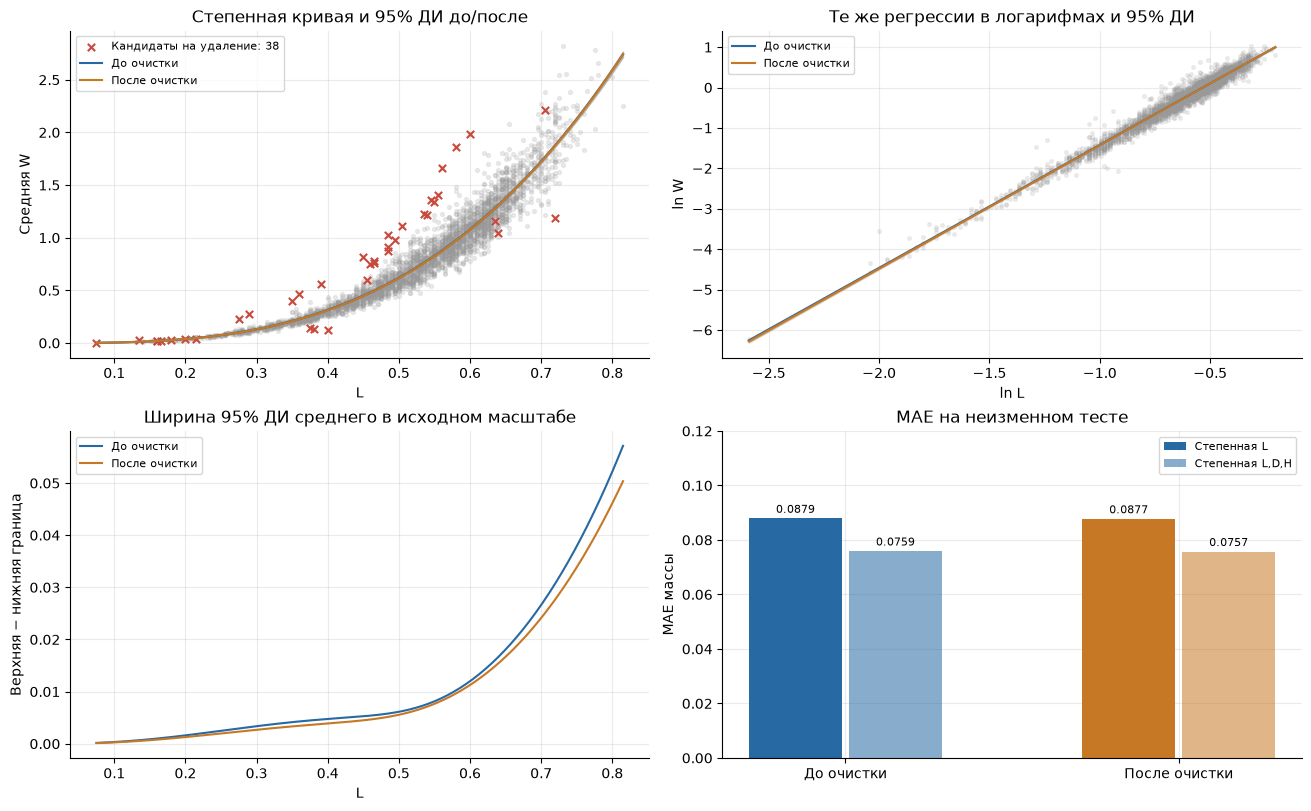

In [18]:
# Очистка: кривые, интервалы и контрольная ошибка
before, after = power_fit, clean_fits["Степенная L"]
central_lo, central_hi = clean_train.length.quantile([.025, .975])
common_grid = np.linspace(a_train.length.min(), a_train.length.max(), 250)
fig, axes = plt.subplots(2, 2, figsize=(13, 8), layout="constrained")
removed = a_train.loc[~a_train.index.isin(clean_train.index)]
axes[0, 0].scatter(a_train.length, a_train.whole_weight, color=".6", s=8, alpha=.18)
axes[0, 0].scatter(removed.length, removed.whole_weight, color=RED, marker="x", s=28, label=f"Кандидаты на удаление: {len(removed)}")
for fit, frame, color, label in [(before, a_train, BLUE, "До очистки"), (after, clean_train, ORANGE, "После очистки")]:
    gx = pd.DataFrame({"length": common_grid})
    lo, hi = interval(fit, np.log(common_grid))
    mean = predict_mass(fit, gx)
    axes[0, 0].plot(common_grid, mean, color=color, label=label)
    axes[0, 0].fill_between(common_grid, np.exp(lo) * fit["smear"], np.exp(hi) * fit["smear"], color=color, alpha=.22)
    axes[0, 1].plot(np.log(common_grid), predict(fit, np.log(common_grid)), color=color, label=label)
    axes[0, 1].fill_between(np.log(common_grid), lo, hi, color=color, alpha=.2)
    axes[1, 0].plot(common_grid, (np.exp(hi) - np.exp(lo)) * fit["smear"], color=color, label=label)
axes[0, 1].scatter(np.log(a_train.length), np.log(a_train.whole_weight), color=".6", s=7, alpha=.15)
axes[0, 0].set(title="Степенная кривая и 95% ДИ до/после", xlabel="L", ylabel="Средняя W")
axes[0, 1].set(title="Те же регрессии в логарифмах и 95% ДИ", xlabel="ln L", ylabel="ln W")
axes[1, 0].set(title="Ширина 95% ДИ среднего в исходном масштабе", xlabel="L", ylabel="Верхняя − нижняя граница")
clean_cv = {name: [] for name in ["Степенная L", "Степенная L,D,H"]}
for tr, va in folds.split(a_train):
    fold_clean, _ = clean_training(a_train.iloc[tr])
    for name in clean_cv:
        fit = fit_abalone(fold_clean, name)
        clean_cv[name].append(mean_absolute_error(a_train.iloc[va].whole_weight, predict_mass(fit, a_train.iloc[va])))
for j, name in enumerate(clean_cv):
    values = [results["abalone_scores"][name]["mae"], mean_absolute_error(a_test.whole_weight, predict_mass(clean_fits[name], a_test))]
    axes[1, 1].bar(np.array([0, 1]) + j * .30, values, width=.28, color=[BLUE, ORANGE], alpha=1 if j == 0 else .55, label=name)
    for x, value in zip(np.array([0, 1]) + j * .30, values):
        axes[1, 1].annotate(f"{value:.4f}", (x, value), xytext=(0, 4), textcoords="offset points", ha="center", fontsize=8)
    results.setdefault("clean_scores", {})[name] = {"mae": values[1], "cv_mae": np.mean(clean_cv[name]), "cv_before": np.mean(cv_errors[name])}
    delta = test_errors[name] - np.abs(a_test.whole_weight.to_numpy() - predict_mass(clean_fits[name], a_test))
    results["clean_scores"][name]["delta_ci"] = np.quantile(delta[indices].mean(axis=1), [.025, .975]).tolist()
axes[1, 1].set(xticks=[.15, 1.15], xticklabels=["До очистки", "После очистки"], title="MAE на неизменном тесте", ylabel="MAE массы", ylim=(0, .12))
for ax in axes.ravel(): ax.grid(); ax.legend(fontsize=8)
figure(fig, "09_abalone_cleaning.png")
results["power_clean"] = {"beta": after["beta"].tolist(), "ci": coefficient_ci(after).tolist(), "smear": after["smear"], "sigma": np.sqrt(after["mse"])}

**Результат очистки:** из 3131 обучающих строк отмечено 38 (27 по остаткам, 11 по геометрии; считаем объединение). У показателя b оценка меняется с 3.0425 до 3.0532; 95% ДИ после очистки [3.0359; 3.0705]. При L=0,5 ширина 95% ДИ среднего W уменьшается с 0.00613 до 0.00556.

MAE степенной модели одной длины на прежнем тесте: 0.08791 → 0.08774, 95% ДИ уменьшения ошибки [-0.00003; 0.00038] включает ноль. Для трёх размеров: 0.07592 → 0.07573. Убедительного тестового выигрыша очистка не показала. CV также меняется мало: для одной длины 0.08559 → 0.08534.

Интервалы и коэффициенты действительно меняются после очистки, но меньшая
ширина ДИ ещё не доказывает улучшение. Критерий пользы — ошибка на прежних
тестовых объектах, в том числе необычных. Удаление хвостов может искусственно
сузить интервал и ухудшить охват новых наблюдений.

### 2.3. Уравнение, область использования и прогнозный интервал

Показываем простую степенную модель после очистки, пригодную для объяснения
преобразования. Для практического прогноза несколькими размерами можно
пользоваться многомерной моделью из сравнения. Рекомендуемая область
простой формулы — центральные 95% обучающих длин: это правило достаточной
плотности данных, а не доказанная физическая граница. На краях данных мало;
за наблюдаемым диапазоном неопределённость экстраполяции этими ДИ не описана.

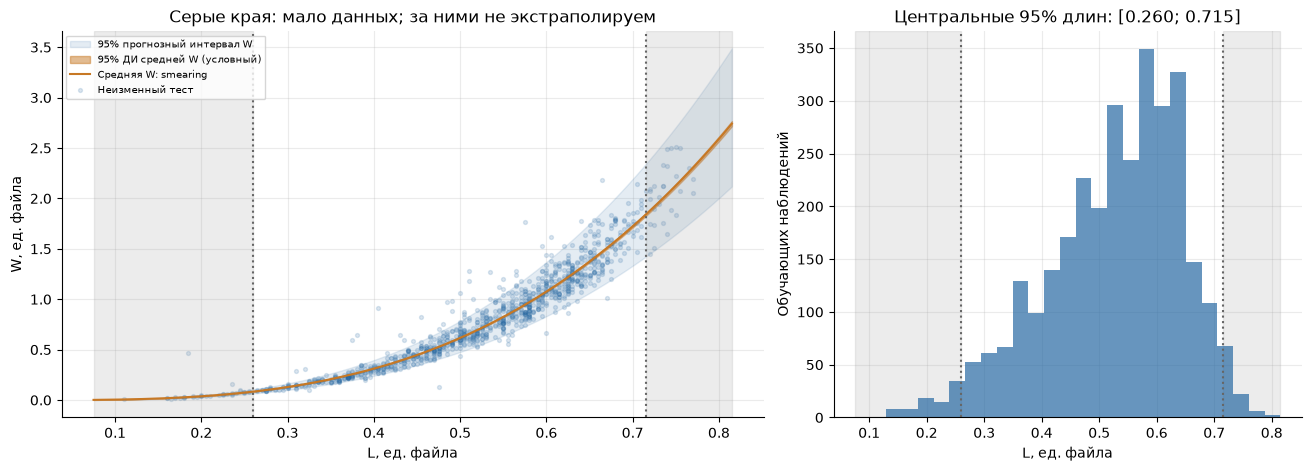

In [19]:
# Область применимости и отличие доверительного от прогнозного интервала
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained", gridspec_kw={"width_ratios": [1.5, 1]})
lo, hi = interval(after, np.log(common_grid))
plo, phi = interval(after, np.log(common_grid), observation=True)
grid_frame = pd.DataFrame({"length": common_grid})
axes[0].fill_between(common_grid, np.exp(plo), np.exp(phi), color=BLUE, alpha=.12, label="95% прогнозный интервал W")
axes[0].fill_between(common_grid, np.exp(lo) * after["smear"], np.exp(hi) * after["smear"], color=ORANGE, alpha=.5, label="95% ДИ средней W (условный)")
axes[0].plot(common_grid, predict_mass(after, grid_frame), color=ORANGE, label="Средняя W: smearing")
axes[0].scatter(a_test.length, a_test.whole_weight, s=8, alpha=.16, color=BLUE, label="Неизменный тест")
for ax in axes:
    ax.axvspan(common_grid.min(), central_lo, color=".6", alpha=.18)
    ax.axvspan(central_hi, common_grid.max(), color=".6", alpha=.18)
    ax.axvline(central_lo, color=".4", ls=":"); ax.axvline(central_hi, color=".4", ls=":")
    ax.grid()
axes[0].set(title="Серые края: мало данных; за ними не экстраполируем", xlabel="L, ед. файла", ylabel="W, ед. файла")
axes[0].legend(fontsize=7, loc="upper left")
axes[1].hist(clean_train.length, bins=25, color=BLUE, alpha=.7)
axes[1].set(title=f"Центральные 95% длин: [{central_lo:.3f}; {central_hi:.3f}]", xlabel="L, ед. файла", ylabel="Обучающих наблюдений")
figure(fig, "10_abalone_domain_intervals.png")
interval_scores = {}
for label, fit in [("before", before), ("after", after)]:
    low, high = interval(fit, np.log(a_test.length), observation=True)
    inside = (np.log(a_test.whole_weight) >= low) & (np.log(a_test.whole_weight) <= high)
    mean_low, mean_high = interval(fit, np.log([.5]))
    interval_scores[label] = {
        "coverage": inside.mean(), "width": np.mean(np.exp(high) - np.exp(low)),
        "mean_ci_width_at_0.5": float((np.exp(mean_high[0]) - np.exp(mean_low[0])) * fit["smear"]),
    }
results["interval_scores"] = interval_scores
results["length_domain"] = {"observed": [a_train.length.min(), a_train.length.max()], "central": [central_lo, central_hi]}
results["geometry_equation"] = {"beta": clean_fits["Степенная L,D,H"]["beta"].tolist(), "smear": clean_fits["Степенная L,D,H"]["smear"]}

**Формула после очистки** в масштабе CSV:

$$\widehat{W}_{geom}=5.0786L^{3.0532},\qquad \widehat{E[W\mid L]}\approx 5.1200L^{3.0532}.$$

Первое выражение — геометрическое среднее (медиана при симметричном логарифмическом шуме), второе учитывает smearing. Для отдельных объектов в логарифмах:

$$\ln W_{new}(L)\approx 1.6250+3.0532\ln L\ \pm\ t_{n-2;0.975}\,0.1271\sqrt{1+h(L)},$$

где $h(L)=1/n+(\ln L-\overline{\ln L})^2/\sum_i(\ln L_i-\overline{\ln L})^2$; обе границы затем экспоненцируются.

Рекомендуемая центральная область L ∈ **[0.260; 0.715]**, полный наблюдаемый обучающий диапазон [0.075; 0.815]. Для формулы трёх размеров после очистки:

$$\widehat{E[W\mid L,D,H]}\approx 10.4643L^{1.5928}D^{0.9436}H^{0.4096}.$$

Последнюю формулу применяем только для положительных размеров в области совместной поддержки обучения; один допустимый диапазон L не гарантирует допустимость любых сочетаний D,H.

**Проверка интервалов на 1044 неизменных тестовых строках:** до очистки охват 94.9%, после — 93.5%; средняя ширина прогнозного интервала 0.449 → 0.409. Более узкий интервал после удаления необычных объектов хуже покрывает исходный тест.

Номинальные 95% прогнозные интервалы требуют проверки: фактический охват
теста указан выше, его не подгоняли до 95%. Интервал среднего значительно
уже интервала отдельного животного, потому что не включает весь естественный
разброс массы. После очистки охват нужно проверять на исходном тесте.
В интервале средней W неопределённость smearing отдельно не учтена;
поэтому он условный и приближённый. Точнее оценить его можно bootstrap
с повторной оценкой поправки и процедуры очистки.

> Исторический вывод по прежнему условию; актуальный выбор — Crabs + Yacht выше.

## Архив 3. Поиск замены Abalone: проверка реальных кандидатов

**Статус: окончательная замена пока не выбрана.** Условие отбора — выраженная
нелинейная зависимость и отсутствие убедительного добавочного выигрыша от
остальных содержательных признаков. Abalone сохраняем. Ниже фиксируем
проверки двух близких кандидатов, включая результаты, которые мешают их выбрать.
Использованы опубликованные измерения; искусственные строки и случайные
«бесполезные признаки» к данным не добавлялись.

Отсутствие значимости одного коэффициента не доказывает бесполезность признака.
Проверяем также прогноз после преобразования, добавление признаков и более
гибкую модель. Поиск набора исследовательский: эти результаты не являются
независимым подтверждением заранее зарегистрированной гипотезы. Разбиения
и правила очистки явно фиксированы; специально под результат их не выбираем.

### 3.1. Yacht Hydrodynamics: нелинейность сильная, но геометрия всё же полезна

[UCI Yacht Hydrodynamics](https://archive.ics.uci.edu/dataset/243/yacht+hydrodynamics),
Gerritsma, Onnink, Versluis: 308 экспериментальных измерений для 22 форм корпуса.
Локальный файл — `data/yacht_hydrodynamics.data`, лицензия UCI CC BY 4.0.
Предикторы: положение центра плавучести, призматический коэффициент,
отношения длины к водоизмещению, ширины к осадке, длины к ширине и число Фруда F.
Цель R — остаточное сопротивление на единицу веса водоизмещения; все столбцы
в опубликованной безразмерной шкале. В отличие от исходной цели Abalone,
здесь используем именно целевую величину, указанную источником.

Проверяем приближение R ≈ A exp(bF), то есть ln R ≈ a + bF.
Одна форма корпуса измерена на нескольких скоростях. Поэтому в тест целиком
откладываем **7 корпусов**, а обучение содержит остальные 15. Фолды также
разделены по корпусам. Это проверка переноса на новые формы, без смешивания
строк одного корпуса между обучением и проверкой.

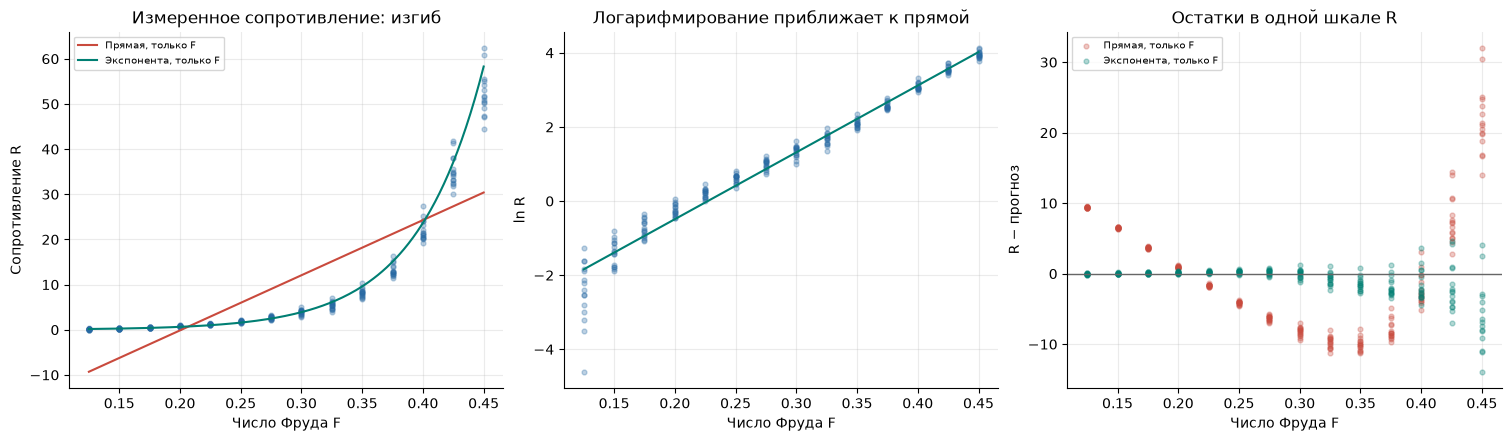

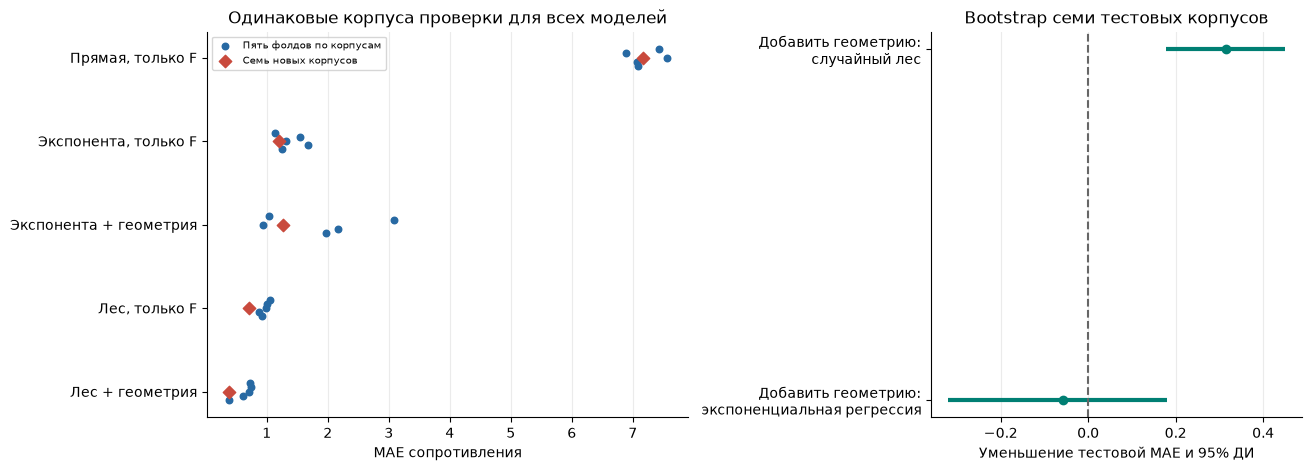

In [20]:
# Реальный кандидат UCI: разбиение целыми корпусами и сравнение признаков
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, GroupShuffleSplit, RepeatedKFold

yacht_columns = ["lcb", "prismatic", "length_displacement", "beam_draught",
                 "length_beam", "froude", "resistance"]
yacht = pd.read_csv(BASE / "data/yacht_hydrodynamics.data", sep=r"\s+", names=yacht_columns)
assert yacht.shape == (308, 7) and not yacht.isna().any().any()
assert yacht[["froude", "resistance"]].gt(0).all().all()
yacht_hulls = yacht.groupby(yacht_columns[:5], sort=True).ngroup().to_numpy()
assert len(np.unique(yacht_hulls)) == 22
y_tr, y_te = next(GroupShuffleSplit(n_splits=1, test_size=.30, random_state=SEED).split(yacht, groups=yacht_hulls))
assert set(yacht_hulls[y_tr]).isdisjoint(yacht_hulls[y_te])
yacht_models = {
    "Прямая, только F": ("ols", False, False),
    "Экспонента, только F": ("ols", True, False),
    "Экспонента + геометрия": ("ols", True, True),
    "Лес, только F": ("forest", True, False),
    "Лес + геометрия": ("forest", True, True),
}

def fit_yacht(frame, name):
    kind, logged, geometry_used = yacht_models[name]
    names = yacht_columns[:6] if geometry_used else ["froude"]
    response = np.log(frame.resistance) if logged else frame.resistance.to_numpy()
    if kind == "ols":
        model = ols(frame[names], response)
        residuals = model["error"]
    else:
        model = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=SEED)
        model.fit(frame[names], response)
        residuals = response - model.predict(frame[names])
    smear = float(np.exp(residuals).mean()) if logged else 1.
    return {"model": model, "names": names, "logged": logged,
            "kind": kind, "smear": smear}

def predict_yacht(fitted, frame):
    x = frame[fitted["names"]]
    value = predict(fitted["model"], x) if fitted["kind"] == "ols" else fitted["model"].predict(x)
    return np.exp(value) * fitted["smear"] if fitted["logged"] else value

yacht_cv = {name: [] for name in yacht_models}
for fold_tr, fold_va in GroupKFold(n_splits=5).split(y_tr, groups=yacht_hulls[y_tr]):
    train_frame, valid_frame = yacht.iloc[y_tr[fold_tr]], yacht.iloc[y_tr[fold_va]]
    for name in yacht_models:
        fitted = fit_yacht(train_frame, name)
        yacht_cv[name].append(mean_absolute_error(valid_frame.resistance, predict_yacht(fitted, valid_frame)))
yacht_fits = {name: fit_yacht(yacht.iloc[y_tr], name) for name in yacht_models}
yacht_error = {name: np.abs(yacht.iloc[y_te].resistance.to_numpy() - predict_yacht(fit, yacht.iloc[y_te]))
               for name, fit in yacht_fits.items()}
# Bootstrap целых тестовых корпусов: 14 скоростей одного корпуса зависимы.
test_hulls = np.unique(yacht_hulls[y_te])
yrng = np.random.default_rng(SEED)
hull_draws = yrng.integers(0, len(test_hulls), size=(5000, len(test_hulls)))
yacht_deltas = {}
for baseline, extended in [("Экспонента, только F", "Экспонента + геометрия"),
                           ("Лес, только F", "Лес + геометрия")]:
    per_hull = np.array([(yacht_error[baseline] - yacht_error[extended])[yacht_hulls[y_te] == g].mean()
                         for g in test_hulls])
    yacht_deltas[extended] = {"gain": float(per_hull.mean()),
                              "ci": np.quantile(per_hull[hull_draws].mean(axis=1), [.025, .975]).tolist()}
results["candidate_yacht"] = {
    "status": "not_selected_extra_features_help_flexible_model",
    "n": len(yacht), "train": len(y_tr), "test": len(y_te),
    "train_hulls": len(np.unique(yacht_hulls[y_tr])), "test_hulls": len(test_hulls),
    "scores": {name: {"cv_mae": float(np.mean(yacht_cv[name])), "test_mae": float(err.mean())}
               for name, err in yacht_error.items()},
    "extra_feature_gain": yacht_deltas,
    "log_equation": yacht_fits["Экспонента, только F"]["model"]["beta"].tolist(),
    "smear": yacht_fits["Экспонента, только F"]["smear"],
}

fig, axes = plt.subplots(1, 3, figsize=(15, 4.3), layout="constrained")
train_frame = yacht.iloc[y_tr]
g = np.linspace(train_frame.froude.min(), train_frame.froude.max(), 180)
gf = pd.DataFrame({"froude": g})
axes[0].scatter(train_frame.froude, train_frame.resistance, s=12, alpha=.30, color=BLUE)
for name, color in [("Прямая, только F", RED), ("Экспонента, только F", GREEN)]:
    axes[0].plot(g, predict_yacht(yacht_fits[name], gf), color=color, label=name)
axes[0].set(title="Измеренное сопротивление: изгиб", xlabel="Число Фруда F", ylabel="Сопротивление R")
axes[0].legend(fontsize=7)
axes[1].scatter(train_frame.froude, np.log(train_frame.resistance), s=12, alpha=.30, color=BLUE)
axes[1].plot(g, predict(yacht_fits["Экспонента, только F"]["model"], g), color=GREEN)
axes[1].set(title="Логарифмирование приближает к прямой", xlabel="Число Фруда F", ylabel="ln R")
for name, color in [("Прямая, только F", RED), ("Экспонента, только F", GREEN)]:
    residual = train_frame.resistance - predict_yacht(yacht_fits[name], train_frame)
    axes[2].scatter(train_frame.froude, residual, s=12, alpha=.30, color=color, label=name)
axes[2].axhline(0, color=".4", lw=1)
axes[2].set(title="Остатки в одной шкале R", xlabel="Число Фруда F", ylabel="R − прогноз")
axes[2].legend(fontsize=7)
for ax in axes: ax.grid()
figure(fig, "11_candidate_yacht_linearization.png")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), layout="constrained", gridspec_kw={"width_ratios": [1.3, 1]})
for j, name in enumerate(yacht_models):
    axes[0].scatter(yacht_cv[name], j + np.linspace(-.10, .10, 5), color=BLUE, s=22,
                    label="Пять фолдов по корпусам" if j == 0 else None)
    axes[0].scatter(yacht_error[name].mean(), j, color=RED, marker="D", s=40,
                    label="Семь новых корпусов" if j == 0 else None)
axes[0].set(yticks=range(len(yacht_models)), yticklabels=list(yacht_models),
            xlabel="MAE сопротивления", title="Одинаковые корпуса проверки для всех моделей")
axes[0].invert_yaxis(); axes[0].legend(fontsize=7)
for j, name in enumerate(yacht_deltas):
    v = yacht_deltas[name]
    axes[1].hlines(j, *v["ci"], color=GREEN, lw=3)
    axes[1].scatter(v["gain"], j, color=GREEN)
axes[1].axvline(0, color=".4", ls="--")
axes[1].set(yticks=[0, 1], yticklabels=["Добавить геометрию:\nэкспоненциальная регрессия", "Добавить геометрию:\nслучайный лес"],
            xlabel="Уменьшение тестовой MAE и 95% ДИ", title="Bootstrap семи тестовых корпусов")
for ax in axes: ax.grid(axis="x")
figure(fig, "12_candidate_yacht_extra_features.png")

<!-- candidate_yacht_summary -->
**Результат.** На 210 обучающих строках найдено уравнение $\ln R=-4.0959+18.0362F$. При общей поправке smearing=1.04605 прогноз средней величины $R\approx 0.01741\exp(18.0362F)$. Это эмпирическое приближение в диапазоне измеренных скоростей, а не универсальный закон сопротивления.

На 98 строках семи новых корпусов MAE прямой **7.1673**, экспоненциальной модели **1.2008**. Преобразование полезно. Добавление геометрии в эту регрессию повышает MAE до 1.2594; CV также ухудшается 1.3851 → 1.8379.

**Но вывод о бесполезности геометрии был бы ошибкой.** При одинаковых настройках леса добавление геометрических признаков уменьшает тестовую MAE **0.7027 → 0.3887** (44.7%). Групповой bootstrap даёт 95% ДИ уменьшения MAE [0.1773; 0.4495]. CV подтверждает направление: 0.9670 → 0.6340. Интервал условен относительно обученных моделей и приблизителен: тестовых корпусов всего семь.

**Решение: Yacht не выбираем под строгое условие «остальные параметры не помогают».** Он хорошо демонстрирует нелинейность и одновременно показывает, почему нельзя делать вывод о признаках только по одной форме регрессии.

### 3.2. BluegillLM: дополнительные длины почти дублируют основную

[Описание FSAdata BluegillLM](https://fishr-core-team.github.io/FSAdata/reference/BluegillLM.html):
100 измерений рыб Lepomis macrochirus из Lake Mary, Minnesota.
Три длины — стандартная SL, до развилки хвоста FL, полная TL — измерены в мм,
масса W — в граммах. Файл `data/bluegill_lm.csv` сохранён из
[репозитория авторов пакета](https://raw.githubusercontent.com/fishR-Core-Team/FSAdata/main/data-raw/BluegillLM.csv).
Серийный номер `sernum` — идентификатор; физическим предиктором его не считаем.

Проверяем W ≈ a TL^b и пользу FL, SL сверх TL. Очистка имеет заранее понятное
геометрическое правило: 0 < SL ≤ FL ≤ TL. Строки, нарушающие его, исключаем
из сравнения всех моделей одинаково. Значения по массе не исправляем и не
вычисляем из теоретической формулы. Статистическую очистку дополнительно
проверяем по обучающим логарифмическим остаткам: 3,5 × 1,4826 × MAD;
пороги в каждом фолде оцениваем заново. Отложенные массы для очистки не используем.

Кроме добавления длин в логарифмах, проверяем взаимодействия признаков:
слишком простая расширенная модель может скрыть их полезность. CV — пять
фолдов с десятью повторениями на обучающей части. Фолды зависимы, поэтому
не трактуем 50 ошибок как 50 независимых наблюдений для доверительного интервала.

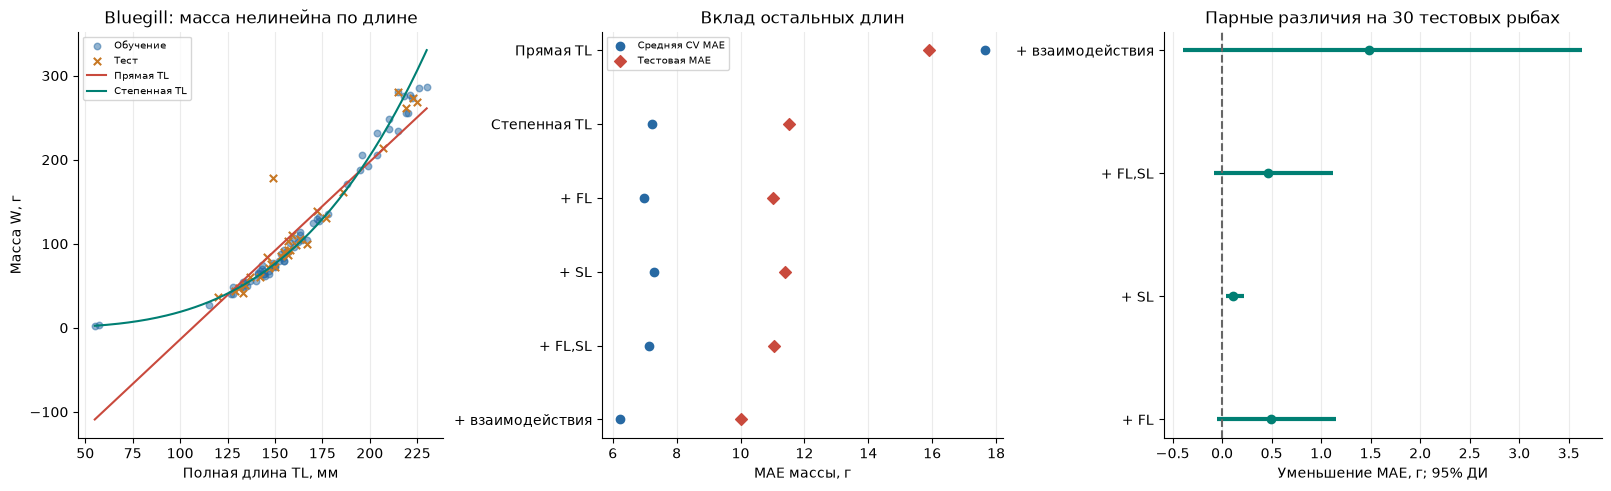

In [21]:
# Второй реальный кандидат: физическая проверка длин и добавочный прогноз
blue_raw = pd.read_csv(BASE / "data/bluegill_lm.csv")
assert blue_raw.shape == (100, 5) and not blue_raw.isna().any().any()
blue_valid = (blue_raw.sl.gt(0) & blue_raw.sl.le(blue_raw.fl) & blue_raw.fl.le(blue_raw.tl) & blue_raw.wght.gt(0))
blue = blue_raw.loc[blue_valid].copy()
b_train, b_test = train_test_split(blue, test_size=.30, random_state=SEED)
blue_specs = ["Прямая TL", "Степенная TL", "+ FL", "+ SL", "+ FL,SL", "+ взаимодействия"]

def blue_x(frame, name):
    if name == "Прямая TL": return frame[["tl"]].to_numpy()
    if name == "Степенная TL": return np.log(frame[["tl"]].to_numpy())
    if name == "+ FL": return np.log(frame[["tl", "fl"]].to_numpy())
    if name == "+ SL": return np.log(frame[["tl", "sl"]].to_numpy())
    values = np.log(frame[["tl", "fl", "sl"]].to_numpy())
    if name == "+ FL,SL": return values
    return np.column_stack([values, values[:, [0]] * values[:, 1:]])

def fit_blue(frame, name):
    logged = name != "Прямая TL"
    fitted = ols(blue_x(frame, name), np.log(frame.wght) if logged else frame.wght)
    fitted["smear"] = float(np.exp(fitted["error"]).mean()) if logged else 1.
    fitted["spec"] = name
    return fitted

def predict_blue(fitted, frame):
    p = predict(fitted, blue_x(frame, fitted["spec"]))
    return np.exp(p) * fitted["smear"] if fitted["spec"] != "Прямая TL" else p

def clean_blue(frame):
    e = fit_blue(frame, "Степенная TL")["error"]
    med = np.median(e)
    scale = max(1.4826 * np.median(np.abs(e - med)), 1e-9)
    return frame.loc[np.abs(e - med) <= 3.5 * scale]

blue_cv = {name: [] for name in blue_specs}
for itr, iva in RepeatedKFold(n_splits=5, n_repeats=10, random_state=SEED).split(b_train):
    fold_train = clean_blue(b_train.iloc[itr])
    for name in blue_specs:
        fit = fit_blue(fold_train, name)
        blue_cv[name].append(mean_absolute_error(b_train.iloc[iva].wght, predict_blue(fit, b_train.iloc[iva])))
b_clean = clean_blue(b_train)
blue_fits = {name: fit_blue(b_clean, name) for name in blue_specs}
blue_errors = {name: np.abs(b_test.wght.to_numpy() - predict_blue(fit, b_test)) for name, fit in blue_fits.items()}
brng = np.random.default_rng(SEED)
blue_boot = brng.integers(0, len(b_test), size=(5000, len(b_test)))
blue_gain = {}
for name in blue_specs[2:]:
    delta = blue_errors["Степенная TL"] - blue_errors[name]
    blue_gain[name] = {"gain": float(delta.mean()), "ci": np.quantile(delta[blue_boot].mean(axis=1), [.025, .975]).tolist()}
results["candidate_bluegill"] = {
    "status": "not_selected_no_proof_other_lengths_unhelpful",
    "n_raw": len(blue_raw), "n_valid": len(blue), "train": len(b_train), "test": len(b_test),
    "invalid_serials": blue_raw.loc[~blue_valid, "sernum"].tolist(),
    "residual_outliers_train": len(b_train) - len(b_clean),
    "scores": {name: {"cv_mae": float(np.mean(blue_cv[name])), "test_mae": float(err.mean())}
               for name, err in blue_errors.items()},
    "extra_feature_gain": blue_gain,
    "log_equation": blue_fits["Степенная TL"]["beta"].tolist(),
    "exponent_ci": coefficient_ci(blue_fits["Степенная TL"])[1].tolist(),
}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), layout="constrained", gridspec_kw={"width_ratios": [1, 1.1, 1.2]})
axes[0].scatter(b_train.tl, b_train.wght, s=22, alpha=.5, color=BLUE, label="Обучение")
axes[0].scatter(b_test.tl, b_test.wght, s=28, marker="x", color=ORANGE, label="Тест")
bg = pd.DataFrame({"tl": np.linspace(blue.tl.min(), blue.tl.max(), 140)})
for name, color in [("Прямая TL", RED), ("Степенная TL", GREEN)]:
    axes[0].plot(bg.tl, predict_blue(blue_fits[name], bg), color=color, label=name)
axes[0].set(title="Bluegill: масса нелинейна по длине", xlabel="Полная длина TL, мм", ylabel="Масса W, г")
axes[0].legend(fontsize=7)
for j, name in enumerate(blue_specs):
    axes[1].scatter(np.mean(blue_cv[name]), j, color=BLUE, label="Средняя CV MAE" if j == 0 else None)
    axes[1].scatter(blue_errors[name].mean(), j, color=RED, marker="D", label="Тестовая MAE" if j == 0 else None)
axes[1].set(yticks=range(len(blue_specs)), yticklabels=blue_specs, xlabel="MAE массы, г", title="Вклад остальных длин")
axes[1].invert_yaxis(); axes[1].legend(fontsize=7)
for j, name in enumerate(blue_gain):
    v = blue_gain[name]
    axes[2].hlines(j, *v["ci"], lw=3, color=GREEN)
    axes[2].scatter(v["gain"], j, color=GREEN)
axes[2].axvline(0, color=".4", ls="--")
axes[2].set(yticks=range(len(blue_gain)), yticklabels=list(blue_gain), xlabel="Уменьшение MAE, г; 95% ДИ", title="Парные различия на 30 тестовых рыбах")
for ax in axes: ax.grid(axis="x")
figure(fig, "13_candidate_bluegill.png")

<!-- candidate_bluegill_summary -->
**Результат очистки и модели.** Исключены две строки с номерами 140 и 1040, нарушающие порядок длин. Остаётся 98 рыб: 68 в обучении, 30 в тесте. Дополнительное правило 3,5 MAD не отметило выбросов в полном обучении (0 строк); удаление наблюдений ради более красивого результата не выполняли.

Для степенной модели $\ln W=-12.8566+3.4303\ln TL$; 95% ДИ показателя степени [3.275; 3.586]. На тесте MAE прямой **15.901 г**, степенной модели **11.507 г**.

Добавление FL и SL уменьшает тестовую MAE до 11.039 г, но 95% ДИ улучшения [-0.079; 1.123] г включает ноль. Это неопределённость выигрыша, а не доказательство его отсутствия. Добавление одной SL даёт небольшой выигрыш 0.112 г с условным парным 95% ДИ [0.037; 0.220] г. Эти отдельные исследовательские сравнения не обеспечивают одновременный 95% уровень.

Взаимодействия дополнительно снижают CV MAE 7.217 → 6.225 г; на тесте 10.028 г, 95% ДИ улучшения [-0.391; 3.632] г. Малая выборка не позволяет надёжно установить размер этого выигрыша.

**Решение: Bluegill ближе к условию, но уверенно утверждать бесполезность остальных длин нельзя.** Сильная взаимосвязь длин сама по себе такого утверждения не доказывает; предпочтительной заменой Abalone этот набор пока не объявляем.

### 3.3. Что означает результат поиска

**Ни один из двух кандидатов пока не выбран взамен Abalone.** Для Yacht
нелинейность выражена хорошо, но геометрические признаки помогают более
гибкому прогнозу. Для Bluegill добавочная польза меньше и менее определённа,
однако из этого не следует, что все остальные длины бесполезны; усложнение
регрессии также меняет результат.

Из других проверок: у LakeTroutALTER добавление пола улучшило тестовый прогноз
при первоначальном сравнении; небольшой набор MASS cats почти не выигрывал от
степенного преобразования; поэтому их также не предлагаем как подтверждённую замену.
Для найденных учебных таблиц маятника доступность и подробность исходных
измерений оказались недостаточными для уверенного выбора именно реальных данных.
Такие материалы не использовались как принятый датасет.

Нельзя обеспечить желаемый ответ выбором случайного разбиения, удалением
полезных столбцов или прекращением проверки на одной неудачной модели.
Следующий кандидат должен пройти обе проверки: выигрыш от линеаризации и
отсутствие воспроизводимого добавочного выигрыша в явно заданной задаче.
Абсолютную бесполезность любых параметров при любых моделях конечная выборка
не устанавливает. Если достаточно *практически малого* выигрыша, допустимый
размер такого выигрыша нужно определить содержательно, до окончательной проверки.

> Исторический вывод по прежнему условию; актуальный выбор — Crabs + Yacht выше.

## Архив 4. Итог выбора датасетов

**Palmer Penguins оставляем:** в задаче двух регрессий есть две полосы,
разный разброс и проверяемое правило отказа; третий вид показывает
ограничение распознавания неизвестных объектов. Для массы имеются
несколько геометрических предикторов. Случайность связи клюва у какого-то
вида этими данными не подтверждается — не подменяем этим желаемым выводом результат.

**Abalone пока сохраняем как исходный вариант:** степенная связь линеаризуется логарифмом, её можно
сравнить с исходной прямой по остаткам и контрольной ошибке. Остальные размеры
помогают прогнозу; это не мешает использовать одну длину для задания на
линеаризацию. Если требование состоит именно в бесполезности любых других
признаков, Abalone ему не соответствует. Для заявленной задачи нелинейности
такой дополнительный критерий не нужен.

Оба набора учебные и описательные: найденные связи не устанавливают
причинность. Все численные выводы относятся к локальным файлам, фиксированному
разбиению и приведённым правилам очистки. Повторные запуски при тех же
версиях библиотек воспроизводят расчёты; текст Markdown содержит результаты
этого фиксированного запуска и при смене данных должен быть обновлён.

**Новый предпочтительный второй датасет пока не утверждён:** результаты реальных кандидатов Yacht и Bluegill приведены в разделе 3. Требование о бесполезности остальных признаков для них не считаем доказанным.

In [22]:
# Сохранение численных результатов для проверки отчёта

def plain(value):
    if isinstance(value, dict):
        return {str(k): plain(v) for k, v in value.items()}
    if isinstance(value, (list, tuple)):
        return [plain(v) for v in value]
    if isinstance(value, np.generic):
        return value.item()
    return value


_ = (OUT / "analysis_results.json").write_text(json.dumps(plain(results), ensure_ascii=False, indent=2))